In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
import statsmodels.api as sm

# --- Style Configuration ---
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "figure.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.3
})

# ---------------- Load 8 CSVs ----------------
csv_paths = [
    # No Filter
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_100k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_100k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_100k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_200k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_200k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_200k/ablation/ablation_results.csv",
    "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_300k/ablation/ablation_results.csv",
    "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_300k/ablation/ablation_results.csv",
    "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_300k/ablation/ablation_results.csv",
    # Filtered
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_100k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_100k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_100k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_200k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_200k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_200k/ablation/ablation_results.csv",
    "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_300k/ablation/ablation_results.csv",
    "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_300k/ablation/ablation_results.csv",
    "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_300k/ablation/ablation_results.csv"
]
dfs = []
for i, path in enumerate(csv_paths):
    try:
        temp_df = pd.read_csv(path)
        temp_df.columns = [c.strip() for c in temp_df.columns]
        # Corrected filter logic: First 3 are 0 (No Filter), next 3 are 1 (Filtered)
        temp_df["filter"] = 0 if i < 3 else 1
        dfs.append(temp_df)
    except FileNotFoundError:
        print(f"Warning: File not found at {path}")

if not dfs:
    raise ValueError("No dataframe loaded. Check paths.")

df = pd.concat(dfs, ignore_index=True)

# ---------------- Cleaning ----------------
metrics = ['mean_rank', 'mean_cosine', 'top1_acc', 'structure_preservation']
for c in metrics:
    if df[c].dtype == object:
        df[c] = df[c].astype(str).str.replace(',', '.').astype(float)
    else:
        df[c] = df[c].astype(float)

binary_cols = ['structure', 'mse', 'cycle', 'con', 'global', 'local', 'tlm', 'filter']
for c in binary_cols:
    df[c] = df[c].astype(int)

# ---------------- Regression & Stats Logic ----------------
RANDOM_SEED = 42
X_pooled = df[binary_cols].values
analysis_results = {}

def get_stars(p):
    if p < 0.001: return '***'
    if p < 0.01: return '**'
    if p < 0.05: return '*'
    return ''

print("\n" + "="*30 + " STATISTICAL SIGNIFICANCE (P-Values) " + "="*30)

for y_col in metrics:
    y = df[y_col].values
    scaler = StandardScaler()
    Xs = scaler.fit_transform(X_pooled)
    
    # Linear Model (Sign)
    lr = LinearRegression().fit(Xs, y)
    
    # Random Forest (Magnitude)
    rf = RandomForestRegressor(n_estimators=1000, random_state=RANDOM_SEED, n_jobs=-1)
    rf.fit(X_pooled, y)
    perm = permutation_importance(rf, X_pooled, y, n_repeats=30, random_state=RANDOM_SEED)
    
    # OLS (Significance)
    X_ols = sm.add_constant(X_pooled) 
    ols_model = sm.OLS(y, X_ols).fit()
    p_values = pd.Series(ols_model.pvalues[1:], index=binary_cols)
    
    print(f"\n--- Metric: {y_col} ---")
    print(p_values.sort_values().to_string())

    sign_lr = np.sign(lr.coef_)
    analysis_results[y_col] = {
        'means': pd.Series(perm.importances_mean * sign_lr, index=binary_cols).sort_values(),
        'stds': pd.Series(perm.importances_std, index=binary_cols),
        'p_values': p_values
    }

# ---------------- Modern Dot Plot ----------------
fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharey=False)
axes = axes.flatten()

POS_COLOR = '#117A65' 
NEG_COLOR = '#A04000'
NS_ALPHA = 0.3       

for i, y_col in enumerate(metrics):
    ax = axes[i]
    res = analysis_results[y_col]
    data_mean = res['means']
    data_std = res['stds'][data_mean.index]
    data_pvals = res['p_values'][data_mean.index]
    
    is_pos_good = y_col != 'mean_rank'
    y_pos = np.arange(len(data_mean))
    
    yticklabels = []
    for idx, (feat_name, val, std, p_val) in enumerate(zip(data_mean.index, data_mean, data_std, data_pvals)):
        is_sig = p_val < 0.05
        alpha = 1.0 if is_sig else NS_ALPHA
        stars = get_stars(p_val)
        yticklabels.append(f"{feat_name} {stars}")

        if (is_pos_good and val > 0) or (not is_pos_good and val < 0):
            color = POS_COLOR
        else:
            color = NEG_COLOR
            
        ax.hlines(idx, val - std, val + std, color=color, linewidth=2, alpha=0.6 * alpha)
        ax.plot(val, idx, 'o', color=color, markersize=8, markeredgecolor='white', markeredgewidth=1, alpha=alpha)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(yticklabels, fontweight='medium')
    ax.axvline(0, color='black', linewidth=1, linestyle='-', alpha=0.4)
    ax.set_title(f"Impact on {y_col.replace('_', ' ').title()}", fontweight='bold', pad=15)
    ax.set_xlabel("Signed Permutation Importance (Δ $R^2$)")
    ax.xaxis.grid(True, linestyle='--', alpha=0.4)

fig.text(0.5, 0.02, "Significance Levels: *** p<0.001, ** p<0.01, * p<0.05. Non-significant (p>0.05) are faded.", ha='center', fontsize=12, style='italic', color='#333333')
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("1_feature_importance_with_pvalues.pdf", bbox_inches='tight')
plt.show()

# ---------------- Top 10 Ranking with Variation ----------------

# 1. Calculate Score PER ROW to get valid Standard Deviation
r_min = df["mean_rank"].min()
r_max = df["mean_rank"].max()

# Create a copy to avoid SettingWithCopy warnings if any

df_scores = df.copy()
df_scores["mean_rank_norm"] = (df_scores["mean_rank"] - r_min) / (r_max - r_min)
df_scores["combined_score"] = (0.25 * df_scores["mean_rank_norm"] + 
                               0.25 * (1 - df_scores["mean_cosine"]) + 
                               0.25 * (1 - df_scores["structure_preservation"]) + 
                               0.25 * (1 - df_scores["top1_acc"]))

# 2. Group by Configuration and Filter, calculating Mean and Std
cols_to_agg = metrics + ["combined_score"]
grouped = df_scores.groupby(["configuration", "filter"])[cols_to_agg].agg(['mean', 'std'])

# 3. Format the table
display_df = pd.DataFrame()
display_df["configuration"] = grouped.index.get_level_values(0)
display_df["filter"] = grouped.index.get_level_values(1)

for col in cols_to_agg:
    # Format: "Mean ± Std"
    m = grouped[col]['mean'].values
    s = grouped[col]['std'].values
    display_df[col] = [f"{mv:.4f} ± {sv:.4f}" for mv, sv in zip(m, s)]

# 4. Sort by Combined Score (Numerical Mean)
# We use the raw mean from the grouped object to sort, as 'combined_score' in display_df is now a string
display_df["_sort_key"] = grouped["combined_score"]["mean"].values
# Lower combined score is better (since it minimizes rank and maximizes others)
display_df = display_df.sort_values("_sort_key", ascending=True).head(10)

# Clean up
display_df = display_df.drop(columns=["_sort_key"])

print("\n" + "="*30 + " TOP 10 CONFIGURATIONS (Mean ± Std) " + "="*30)
# Adjust column width for printing
pd.set_option('display.max_colwidth', None)
print(display_df.to_string(index=False))


============================== STATISTICAL SIGNIFICANCE (P-Values) ==============================

--- Metric: mean_rank ---
con          1.854618e-61
mse          5.883884e-50
cycle        8.404936e-26
tlm          5.139116e-08
structure    5.950478e-04
local        4.195481e-01
global       4.405557e-01
filter       9.956455e-01

--- Metric: mean_cosine ---
con          5.168965e-158
mse           1.272605e-76
cycle         1.404910e-09
structure     1.227589e-07
tlm           6.445683e-03
local         4.709265e-02
global        6.416151e-02
filter        9.939576e-01

--- Metric: top1_acc ---
con          1.446701e-93
mse          8.661252e-51
cycle        3.980720e-20
structure    2.369375e-07
tlm          7.532009e-03
local        4.010108e-01
global       4.544333e-01
filter       9.841150e-01


KeyboardInterrupt: 

In [ ]:
import pandas as pd
import numpy as np

# 1. Copia i dati originali (assumendo che ogni riga sia una coppia src->tgt)
#df_z = df.copy()
df_z = df[df['filter']==0]

# 2. Configurazione Metriche
metrics = ['mean_rank', 'structure_preservation', 'mean_cosine', 'top1_acc']

# 3. Calcolo Z-Score "Per Riga" (su tutto il dataset)
# Normalizziamo ogni esperimento rispetto alla media globale
for col in metrics:
    mean_val = df_z[col].mean()
    std_val = df_z[col].std()
    
    if std_val == 0:
        df_z[f'Z_{col}'] = 0
    else:
        df_z[f'Z_{col}'] = (df_z[col] - mean_val) / std_val

# 4. Inversione Mean Rank (Basso è meglio -> Z positivo)
df_z['Z_mean_rank'] = df_z['Z_mean_rank'] * -1

# 5. Calcolo Z-Score Totale per la singola coppia
# Questo rappresenta la qualità di QUELLO specifico esperimento src->tgt
df_z['PAIR_Z_SCORE'] = (
    df_z['Z_mean_rank'] + 
    df_z['Z_structure_preservation'] + 
    df_z['Z_mean_cosine'] + 
    df_z['Z_top1_acc']
)

# 6. Aggregazione per Configurazione: Media e Varianza tra le coppie
# Qui otteniamo la risposta alla tua richiesta:
# - mean: "Quanto è brava in media?"
# - std: "Quanto varia tra una coppia e l'altra?"
grouped = df_z.groupby(by=['configuration'])['PAIR_Z_SCORE'].agg(['mean', 'std', 'count'])

# 7. Creazione DataFrame Finale
results = pd.DataFrame()
results['configuration'] = grouped.index
results['Z_Mean'] = grouped['mean'].values  # Media degli Z-score
results['Z_Std'] = grouped['std'].values    # Varianza (Std Dev) degli Z-score
results['Num_Pairs'] = grouped['count'].values

# 8. Ordinamento: Preferiamo Media Alta e (a parità) Stabilità (Bassa Std)
# Possiamo creare uno score sintetico "Conservative": Media - (0.5 * Std)
# Questo penalizza le configurazioni instabili.
results['Conservative_Score'] = results['Z_Mean'] - (0.5 * results['Z_Std'].fillna(0))

results = results.sort_values(by='Z_Mean', ascending=False).head(10)

# Formattazione per la stampa
print("=== TOP 10 CONFIGURAZIONI (Stabilità & Performance) ===")
print("Z_Mean: Performance Media | Z_Std: Instabilità (Varianza)")
print("-" * 80)
print(results[['configuration', 'Z_Mean', 'Z_Std', 'Conservative_Score']].to_string(
    index=False, 
    formatters={
        'Z_Mean': '{:.3f}'.format,
        'Z_Std': '{:.3f}'.format,
        'Conservative_Score': '{:.3f}'.format
    }
))

=== TOP 10 CONFIGURAZIONI (Stabilità & Performance) ===
Z_Mean: Performance Media | Z_Std: Instabilità (Varianza)
--------------------------------------------------------------------------------
                 configuration Z_Mean Z_Std Conservative_Score
           con+local+structure  1.709 0.222              1.598
          con+global+structure  1.705 0.246              1.582
             con+tlm+structure  1.697 0.225              1.585
       con+local+tlm+structure  1.696 0.227              1.583
    con+global+local+structure  1.696 0.233              1.580
      con+global+tlm+structure  1.690 0.233              1.574
                 con+structure  1.689 0.219              1.579
       mse+con+local+structure  1.670 0.257              1.542
    cycle+con+global+structure  1.668 0.207              1.564
cycle+con+global+tlm+structure  1.662 0.222              1.551


/tmp/ipykernel_1842565/2983092790.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_z[f'Z_{col}'] = (df_z[col] - mean_val) / std_val
/tmp/ipykernel_1842565/2983092790.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_z[f'Z_{col}'] = (df_z[col] - mean_val) / std_val
/tmp/ipykernel_1842565/2983092790.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https:

/tmp/ipykernel_3623875/2346451688.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_z[f'Z_{col}'] = val_norm
/tmp/ipykernel_3623875/2346451688.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_z[f'Z_{col}'] = val_norm
/tmp/ipykernel_3623875/2346451688.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guid

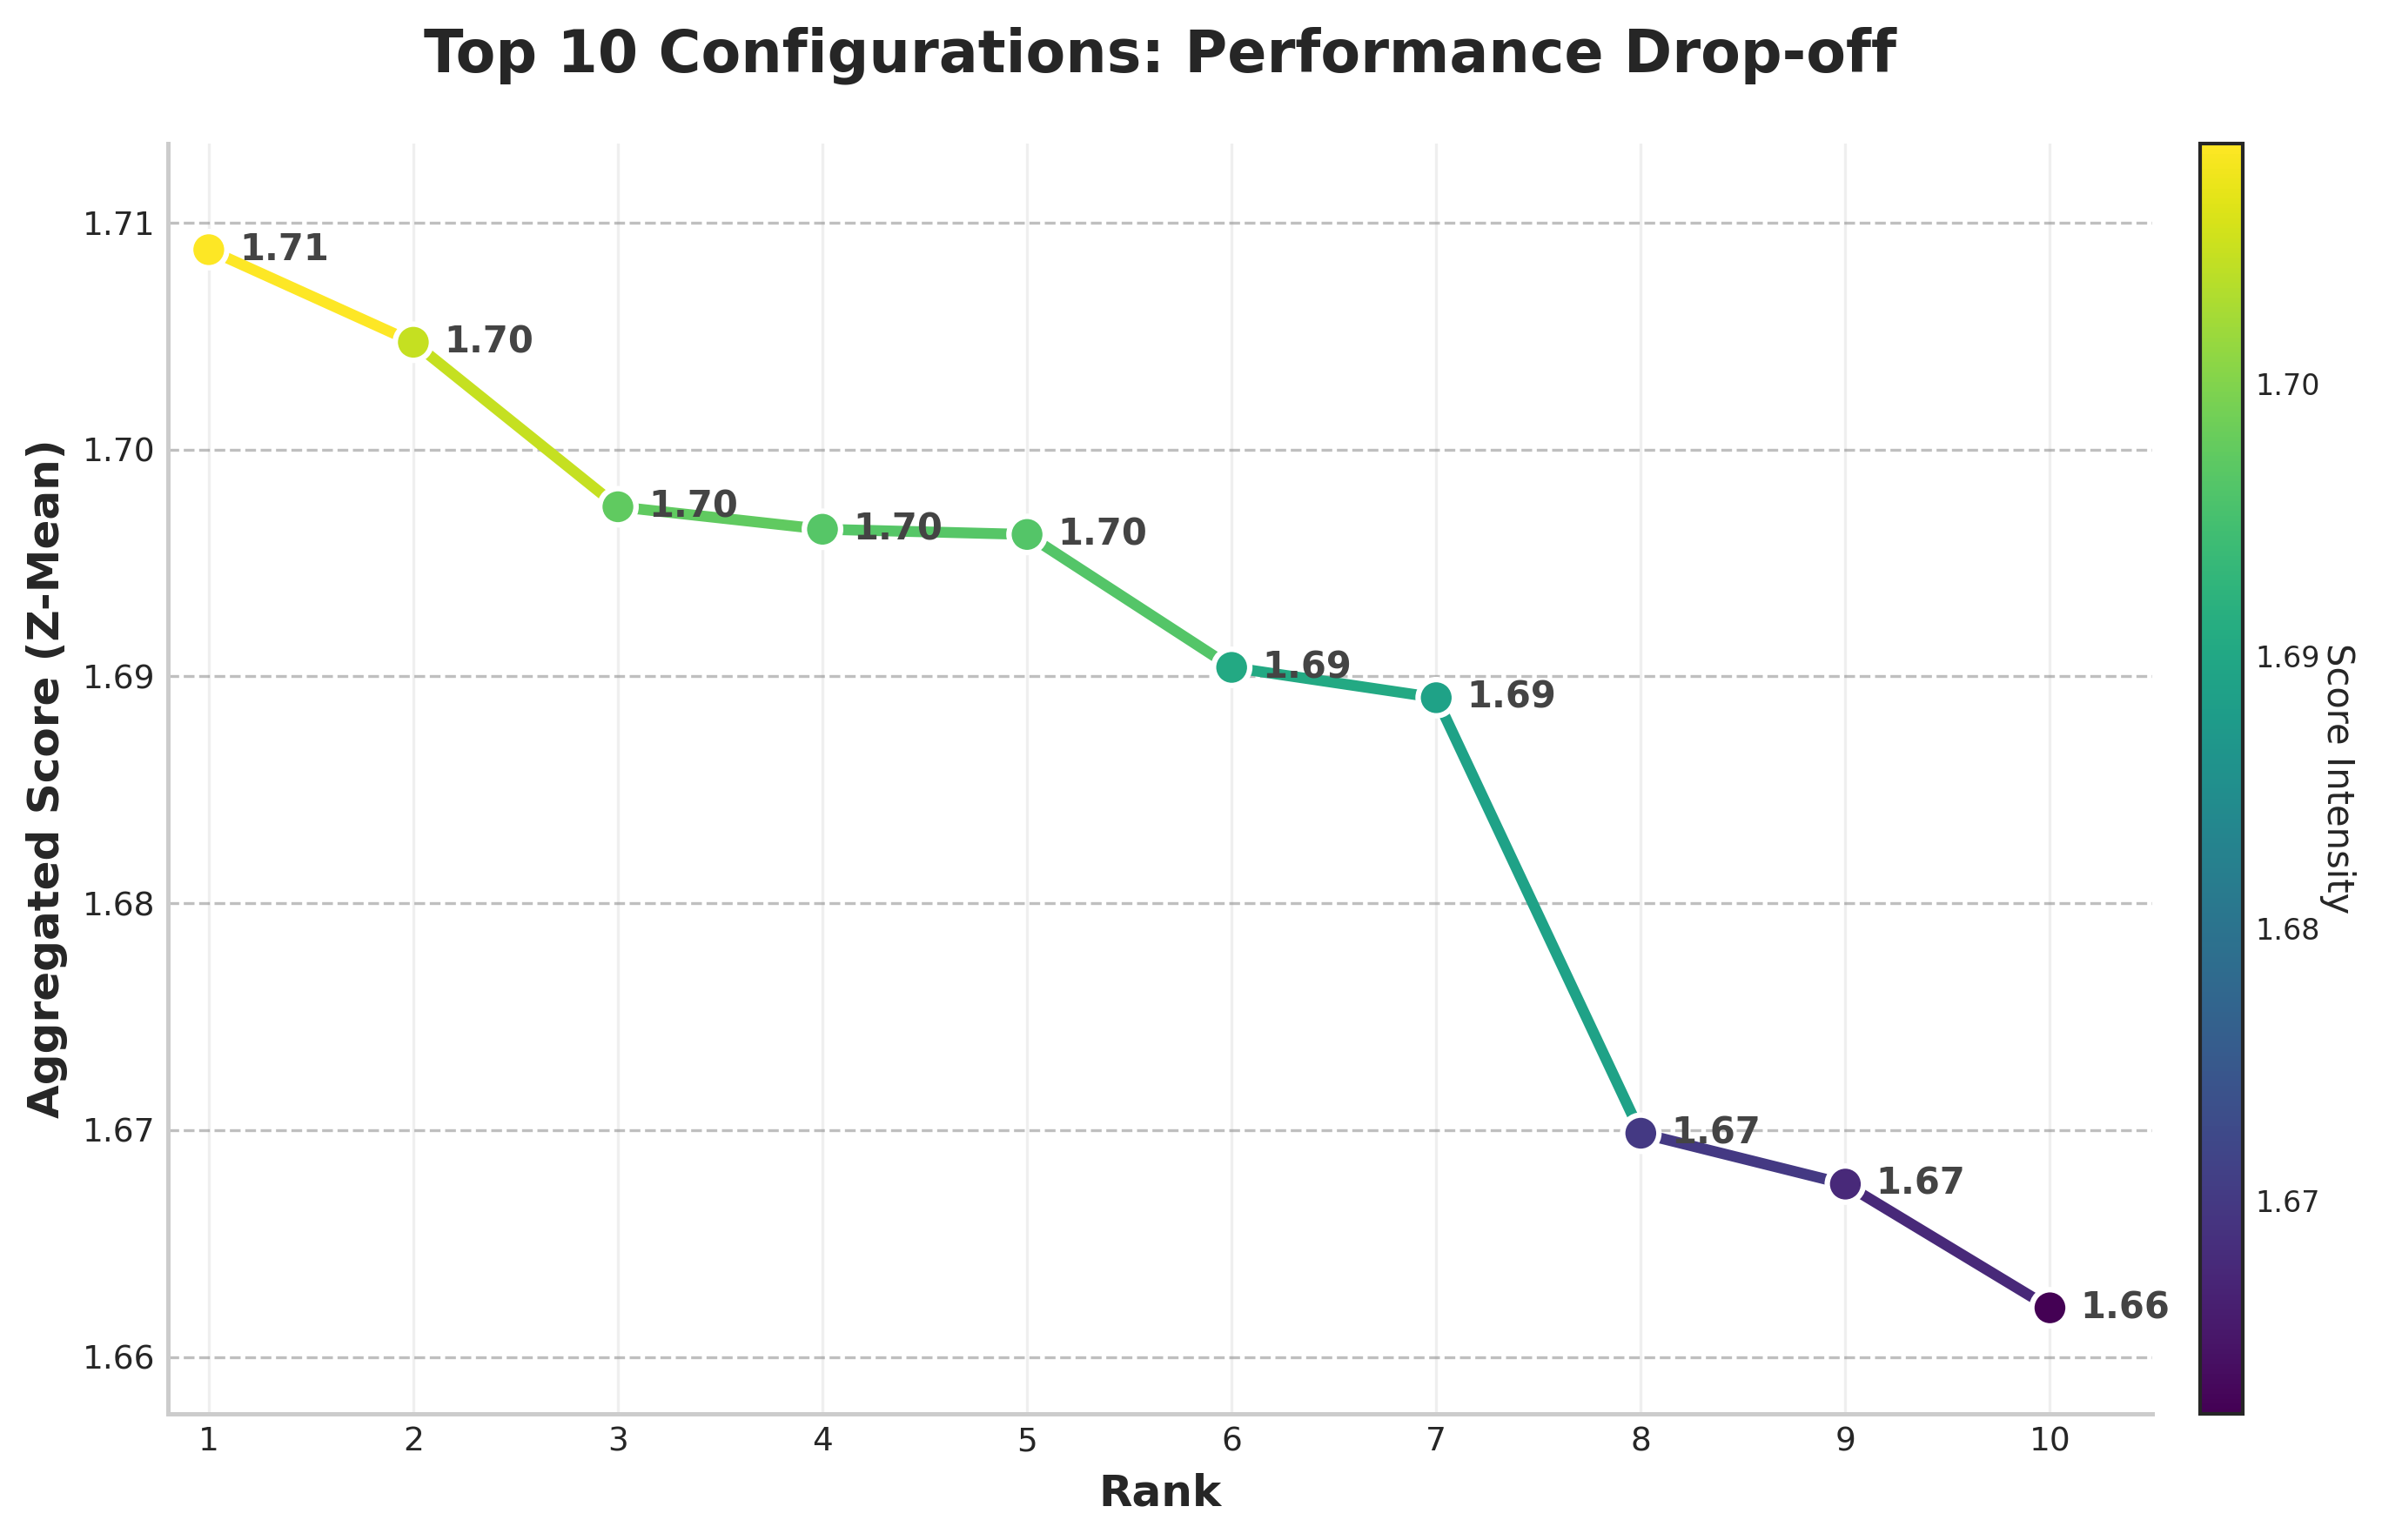

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize

# ==============================================================================
# 1. DATA PREPARATION (Unchanged)
# ==============================================================================
#df_z = df.copy() 
df_z = df[df['filter']==0]

metrics = ['mean_rank', 'structure_preservation', 'mean_cosine', 'top1_acc']

for col in metrics:
    mean_val = df_z[col].mean()
    std_val = df_z[col].std()
    val_norm = (df_z[col] - mean_val) / std_val if std_val != 0 else 0
    df_z[f'Z_{col}'] = val_norm

df_z['Z_mean_rank'] = df_z['Z_mean_rank'] * -1

df_z['PAIR_Z_SCORE'] = (
    df_z['Z_mean_rank'] + 
    df_z['Z_structure_preservation'] + 
    df_z['Z_mean_cosine'] + 
    df_z['Z_top1_acc']
)

grouped = df_z.groupby(['configuration'])['PAIR_Z_SCORE'].mean().reset_index()
grouped = grouped.rename(columns={'PAIR_Z_SCORE': 'Z_Mean'})
top_10 = grouped.sort_values(by='Z_Mean', ascending=False).head(10).reset_index(drop=True)

# ==============================================================================
# 2. PROFESSIONAL GRADIENT LINE PLOT (Smaller Axis Numbers)
# ==============================================================================
plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Helvetica']})
fig, ax = plt.subplots(figsize=(10, 6))
sns.set_style("white")

# X and Y data
x = top_10.index + 1
y = top_10['Z_Mean']

# --- A. CREATE THE GRADIENT LINE ---
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

norm = Normalize(y.min(), y.max())
cmap = plt.get_cmap('viridis') 

lc = LineCollection(segments, cmap=cmap, norm=norm)
lc.set_array(y)
lc.set_linewidth(3)
line = ax.add_collection(lc)

# --- B. ADD MARKERS ---
sc = ax.scatter(x, y, c=y, cmap=cmap, norm=norm, s=100, zorder=10, edgecolors='white', linewidth=1.5)

# --- C. ANNOTATIONS ---
for i in range(len(top_10)):
    score = y[i]
    ax.text(x[i] + 0.15, score, f'{score:.2f}', 
            fontsize=10, color='#444444', va='center', fontweight='bold')

# --- D. SCALING & AXES ---
padding = (y.max() - y.min()) * 0.1
ax.set_xlim(0.8, 10.5)
ax.set_ylim(y.min() - padding, y.max() + padding)

# Titles
ax.set_title('Top 10 Configurations: Performance Drop-off', fontsize=16, weight='bold', pad=20)
ax.set_xlabel('Rank', fontsize=12, weight='bold')
ax.set_ylabel('Aggregated Score (Z-Mean)', fontsize=12, weight='bold')

# Grid
ax.grid(axis='y', linestyle='--', alpha=0.5, color='gray', zorder=0)

# Clean Spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.2)
ax.spines['bottom'].set_linewidth(1.2)

# --- KEY CHANGE: CONTROL TICK SIZE HERE ---
ax.set_xticks(np.arange(1, 11, 1))

# tick_params allows you to change the size ('labelsize') of the numbers
# axis='both' applies it to X and Y. 
# labelsize=9 is smaller than the default (usually 10 or 11).
ax.tick_params(axis='both', which='major', labelsize=9) 

# Colorbar
cbar = plt.colorbar(sc, ax=ax, pad=0.02, aspect=30)
cbar.set_label('Score Intensity', labelpad=10, rotation=270, fontsize=10) # Label size
cbar.ax.tick_params(labelsize=8) # Colorbar number size

plt.tight_layout()
plt.savefig('2_cliff_plot_gradient.pdf', dpi=300)
plt.show()

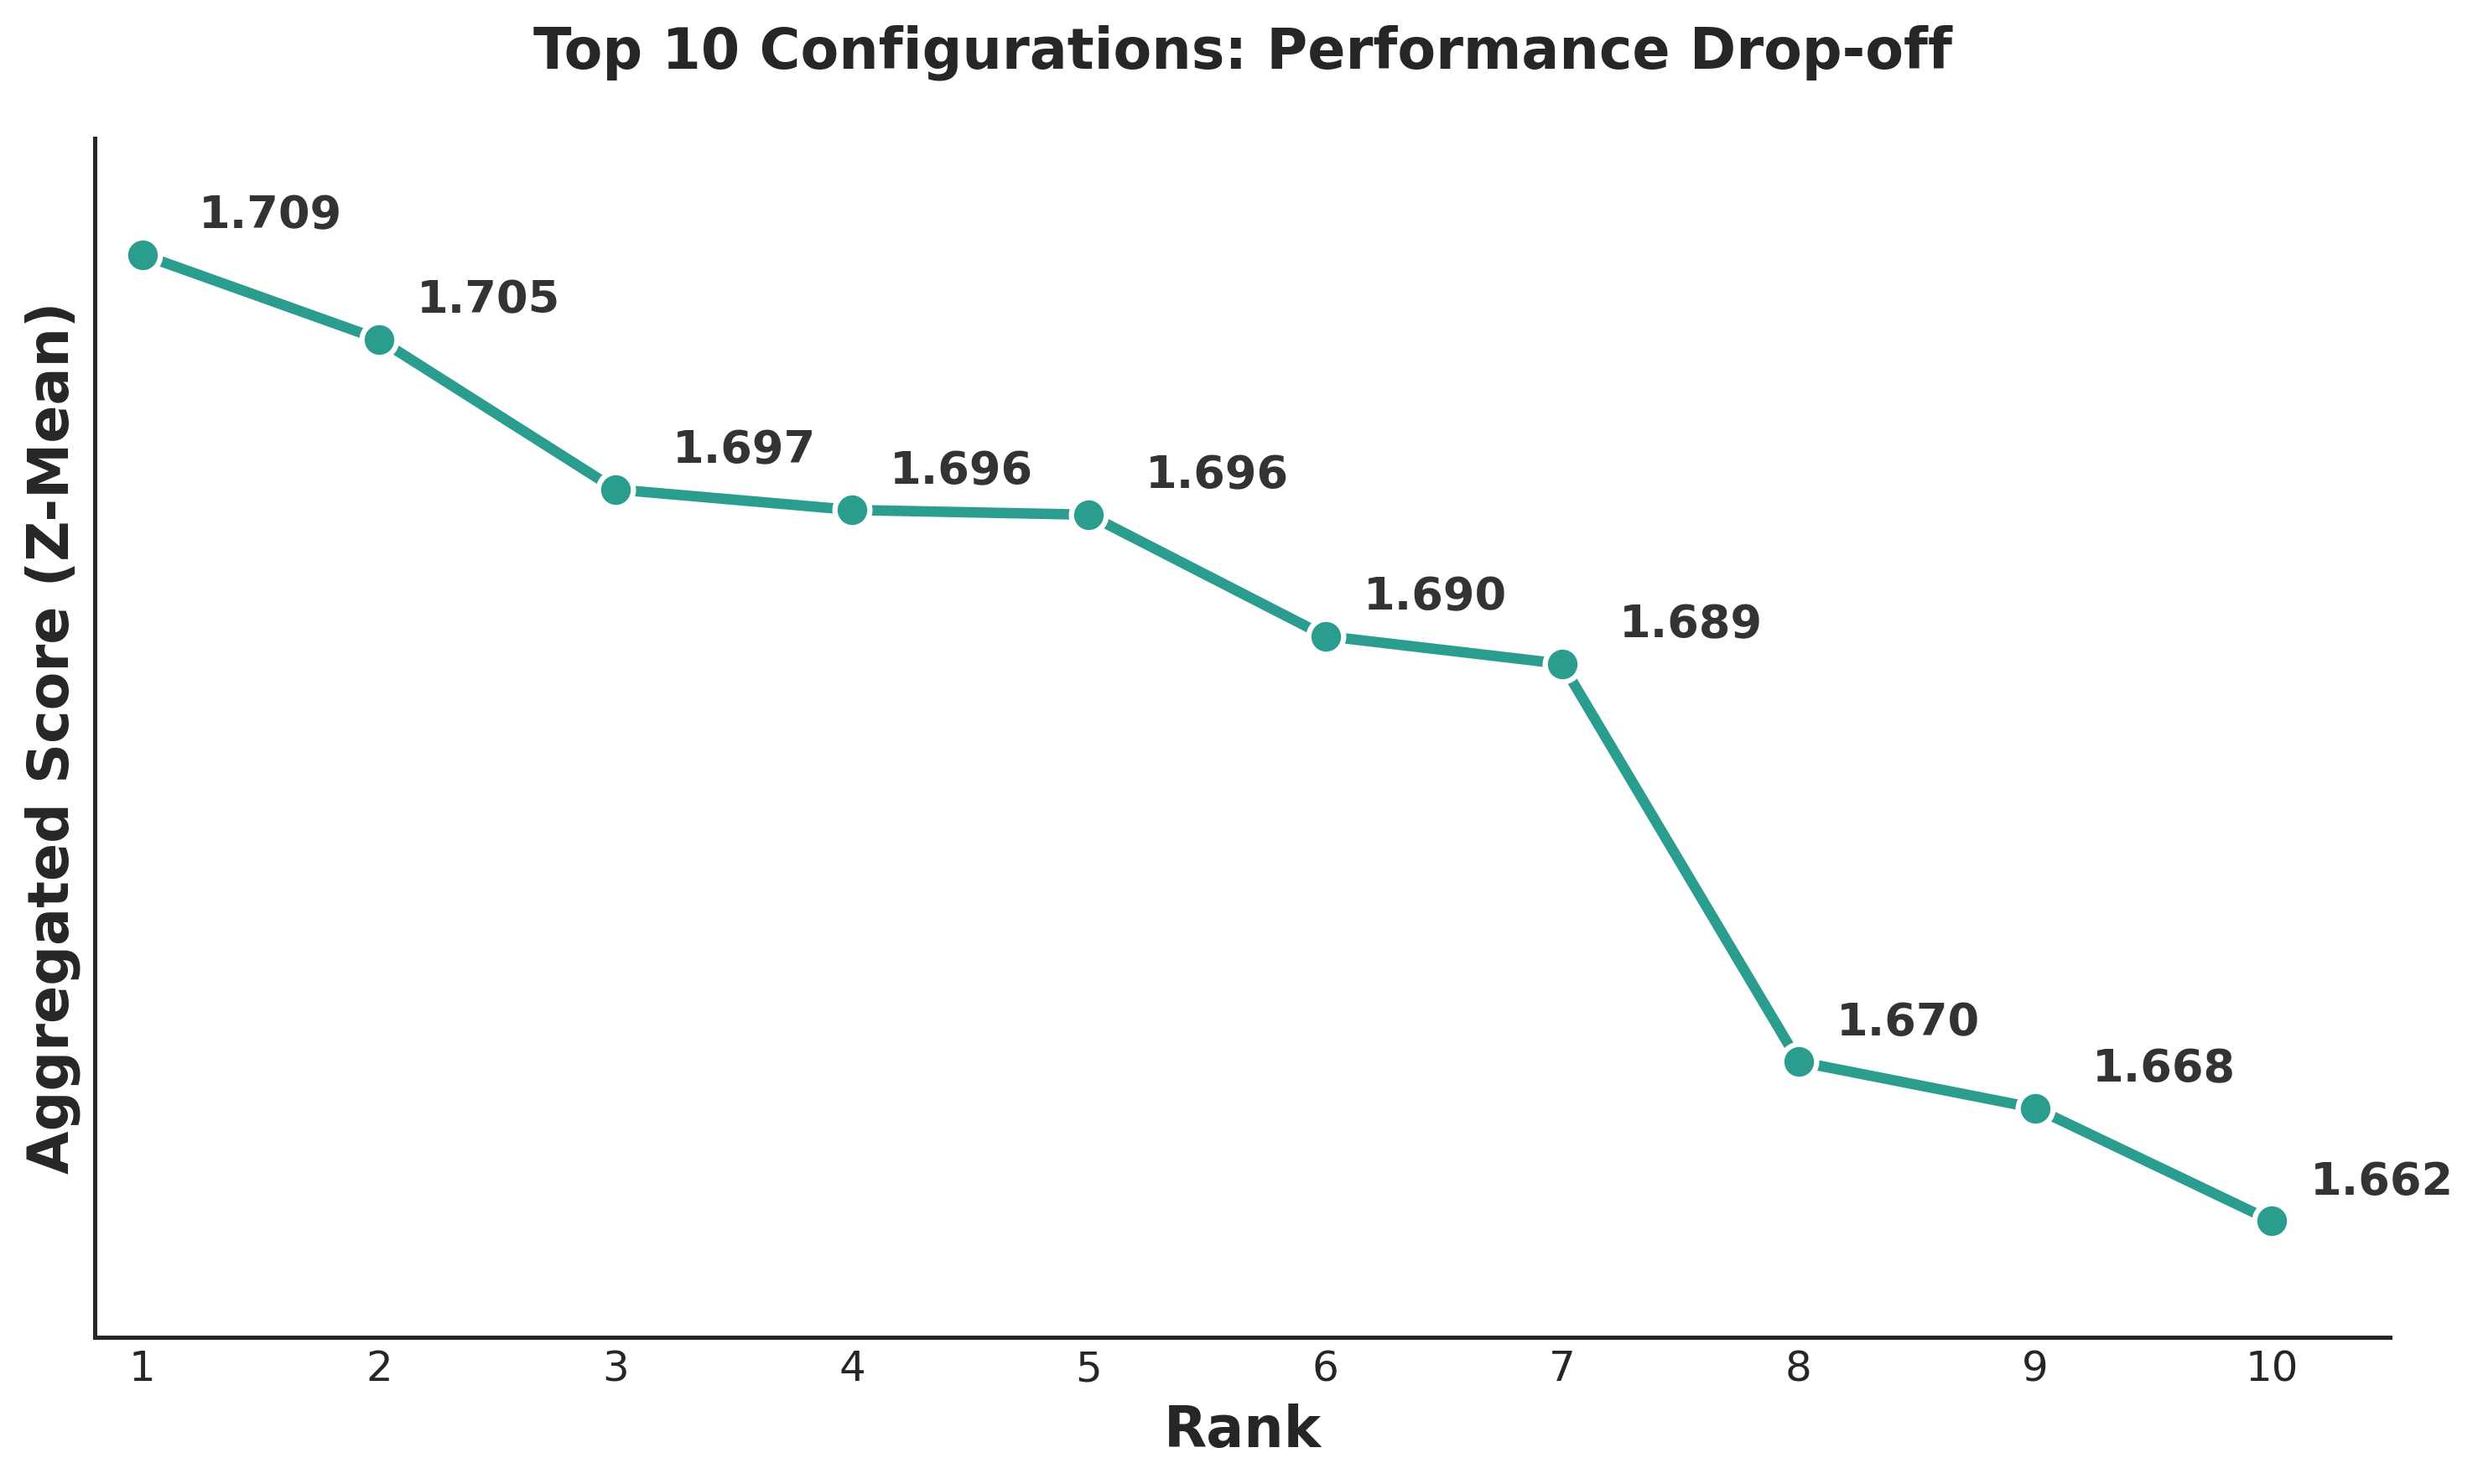

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

# ==============================================================================
# 1. DATA PREPARATION (Unchanged)
# ==============================================================================
df_z = df[df["filter"] == 0].copy()

metrics = ["mean_rank", "structure_preservation", "mean_cosine", "top1_acc"]

for col in metrics:
    mean_val = df_z[col].mean()
    std_val = df_z[col].std()
    df_z[f"Z_{col}"] = (df_z[col] - mean_val) / std_val if std_val != 0 else 0

df_z["Z_mean_rank"] = df_z["Z_mean_rank"] * -1

df_z["PAIR_Z_SCORE"] = (
    df_z["Z_mean_rank"]
    + df_z["Z_structure_preservation"]
    + df_z["Z_mean_cosine"]
    + df_z["Z_top1_acc"]
)

grouped = df_z.groupby(["configuration"])["PAIR_Z_SCORE"].mean().reset_index()
grouped = grouped.rename(columns={"PAIR_Z_SCORE": "Z_Mean"})
top_10 = grouped.sort_values(by="Z_Mean", ascending=False).head(10).reset_index(drop=True)

# ==============================================================================
# 2. PLOT
# ==============================================================================
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica"]})
fig, ax = plt.subplots(figsize=(10, 6))
sns.set_style("white")

x = (top_10.index + 1).to_numpy()
y = top_10["Z_Mean"].to_numpy()

LINE_COLOR = "#2a9d8f"
MARKER_COLOR = "#2a9d8f"
VALUE_FONTSIZE = 13

ax.plot(x, y, linewidth=3, color=LINE_COLOR, zorder=5)
ax.scatter(
    x, y,
    s=100,
    color=MARKER_COLOR,
    zorder=10,
    edgecolors="white",
    linewidth=1.5
)

# --- SMARTER ANNOTATIONS (collision-aware-ish) ---
# Use y-range to scale vertical offset consistently
yr = (y.max() - y.min())
dy = 0.04 * yr if yr > 0 else 0.01  # vertical offset in data units
dx_base = 0.18                      # base horizontal offset in x units (rank units)

# local slope to decide above/below placement
slopes = np.zeros_like(y)
slopes[1:] = y[1:] - y[:-1]

for i in range(len(y)):
    # Alternate tiny x jitter to reduce collisions when points are close
    dx = dx_base + (0.06 if i % 2 == 0 else -0.02)

    # Put label above if trend decreasing (negative slope) else below
    # (you can flip if you prefer)
    place_above = True
    if i > 0:
        place_above = slopes[i] <= 0

    y_text = y[i] + (dy if place_above else -dy)

    ax.text(
        x[i] + dx, y_text, f"{y[i]:.3f}",
        fontsize=VALUE_FONTSIZE,
        color="#333333",
        va="center",
        fontweight="bold",
        zorder=20,
        bbox=dict(boxstyle="round,pad=0.18", facecolor="white", edgecolor="none", alpha=0.85)
    )

# Axes, no grid, no y ticks
padding = 0.12 * yr if yr > 0 else 0.05
ax.set_xlim(0.8, 10.5)
ax.set_ylim(y.min() - padding, y.max() + padding)

ax.set_title("Top 10 Configurations: Performance Drop-off", fontsize=16, weight="bold", pad=20)
ax.set_xlabel("Rank", fontsize=16, weight="bold")
ax.set_ylabel("Aggregated Score (Z-Mean)", fontsize=16, weight="bold")

ax.grid(False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)

ax.set_xticks(np.arange(1, 11, 1))
ax.tick_params(axis="x", which="major", labelsize=12)

ax.set_yticks([])
ax.tick_params(axis="y", which="both", left=False, labelleft=False)

plt.tight_layout()
plt.savefig("2_cliff_plot_gradient.pdf", dpi=300)
plt.show()


 STARTING INTERACTION ANALYSIS FOR ALL METRICS
Processing mean_rank...
Processing mean_cosine...
Processing top1_acc...
Processing structure_preservation...


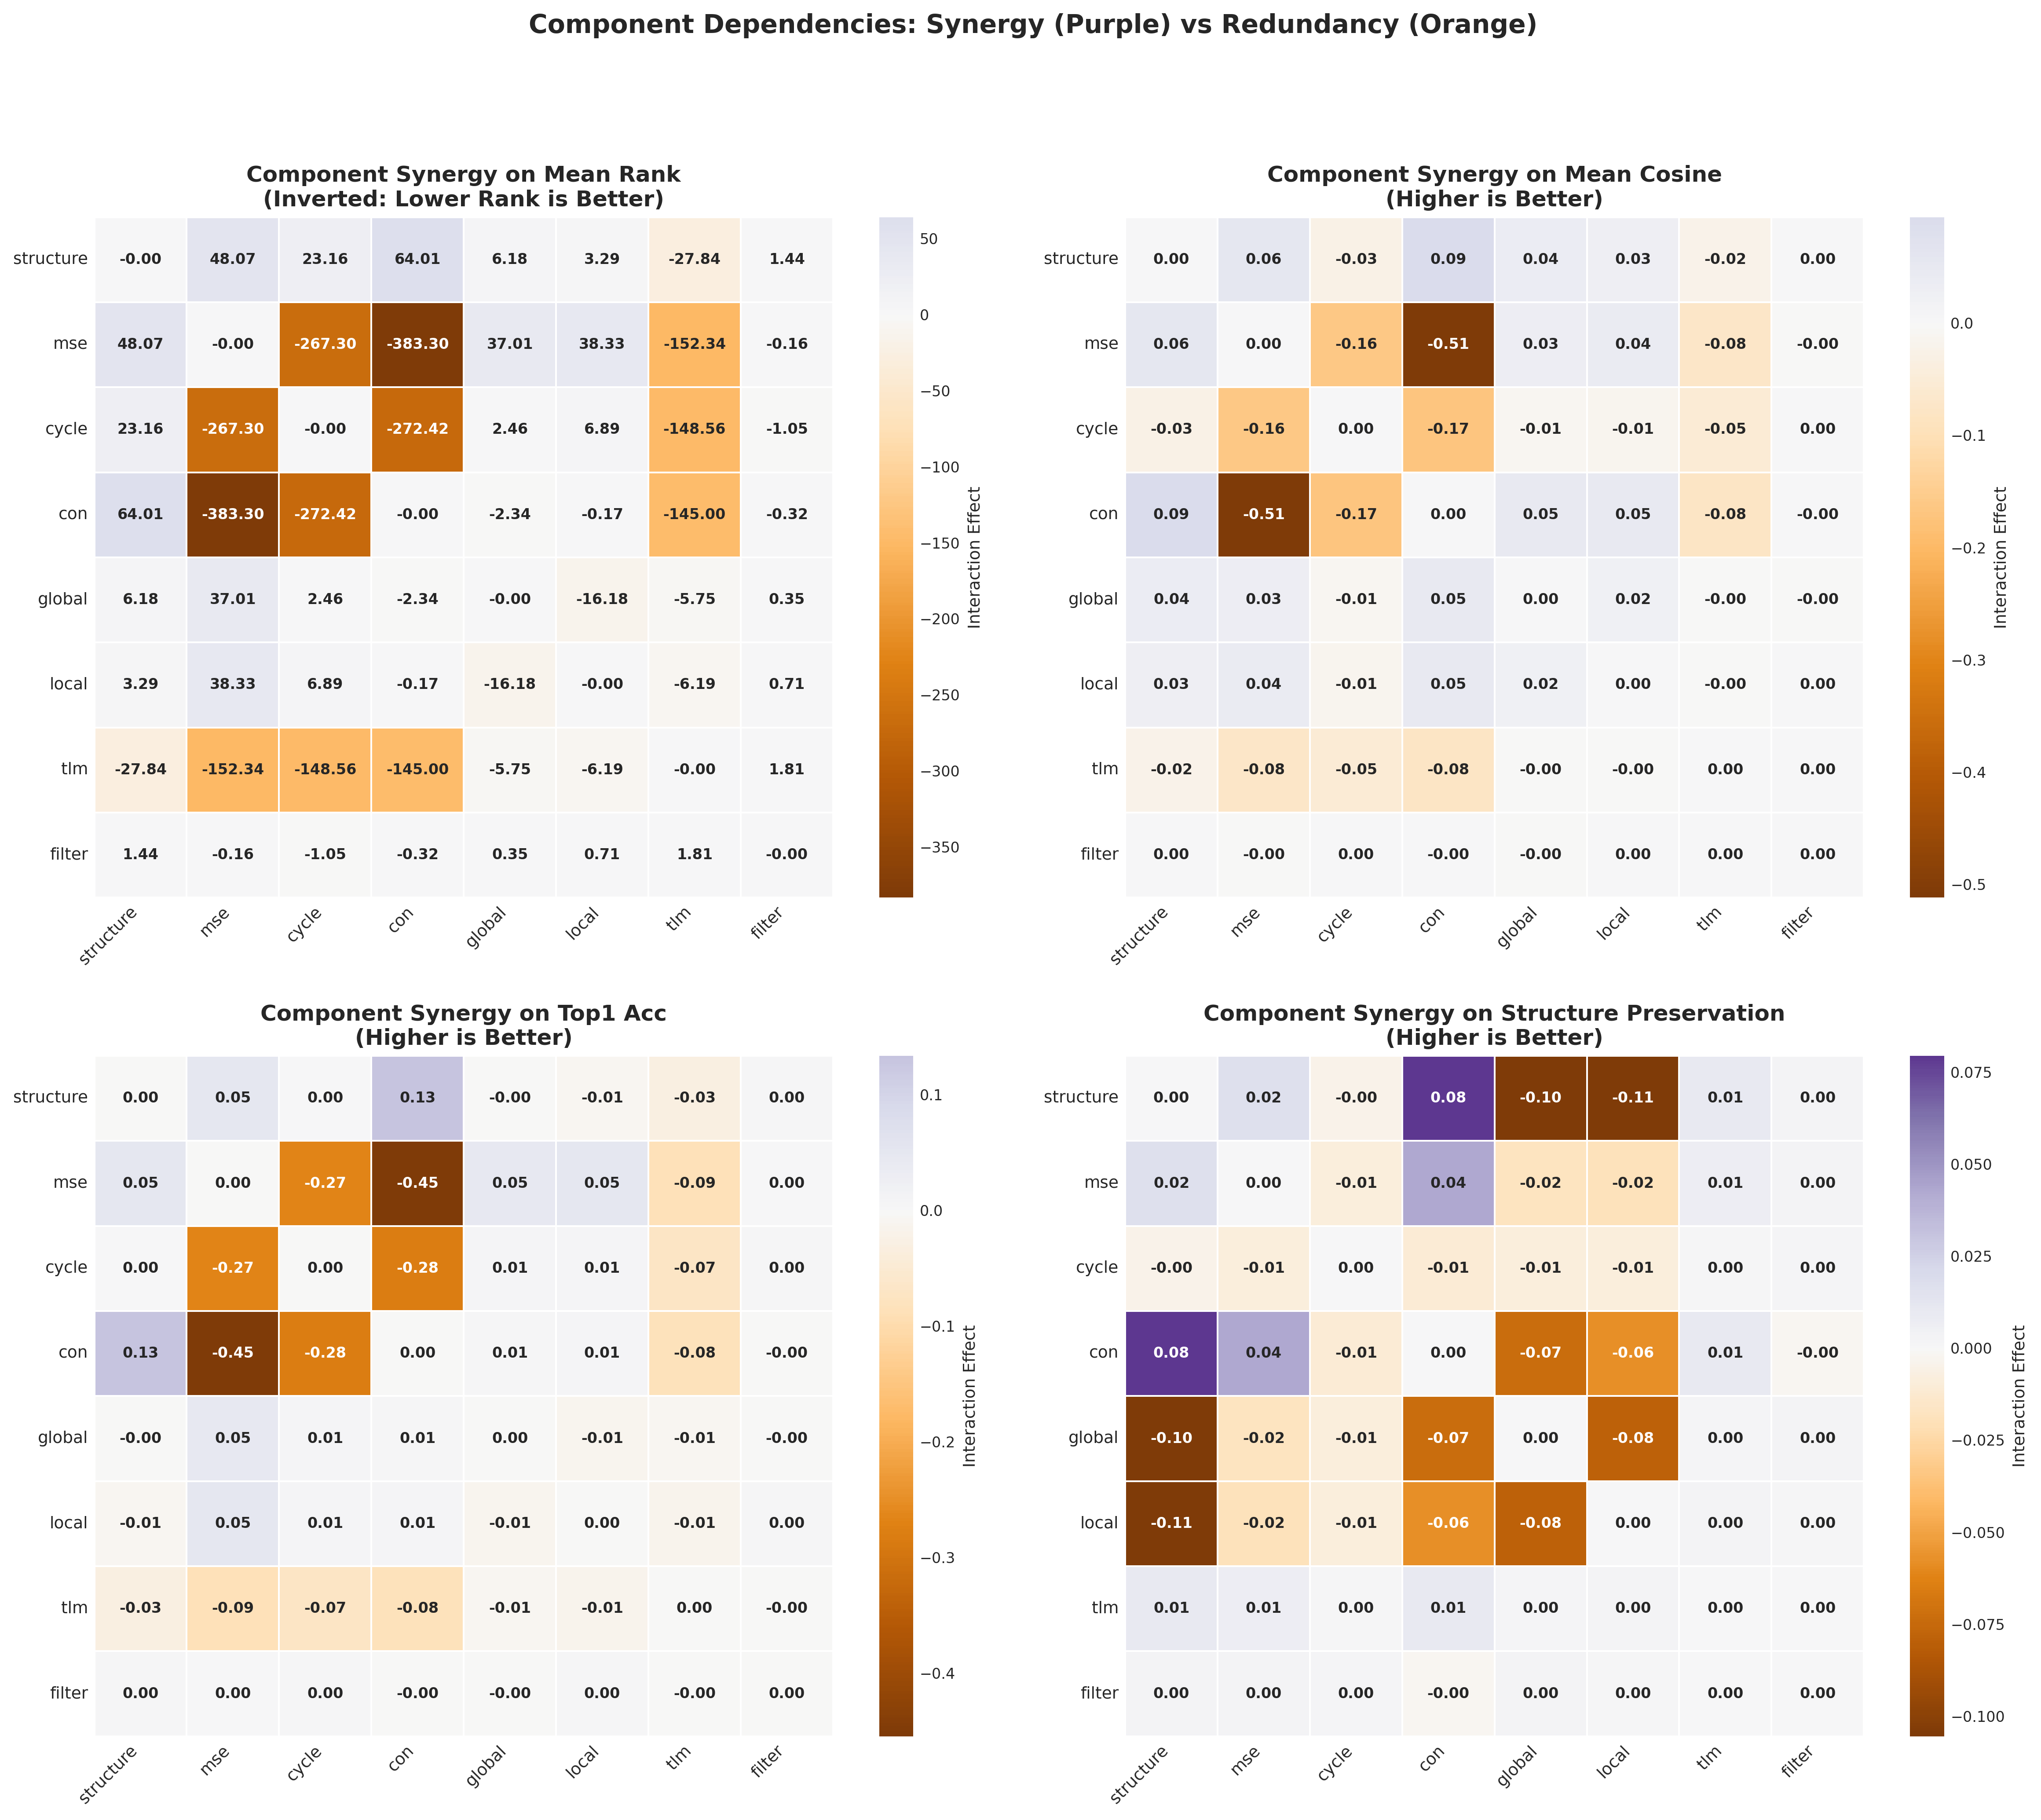


All plots saved to 'dependency_interactions_all_metrics.pdf'


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

# =============================================================================
#             MULTI-METRIC INTERACTION ANALYSIS (PROFESSIONAL SIZE)
# =============================================================================

# 1. Define Metrics and their "Direction"
metrics_config = {
    'mean_rank': {'higher_is_better': False},
    'mean_cosine': {'higher_is_better': True},
    'top1_acc': {'higher_is_better': True},
    'structure_preservation': {'higher_is_better': True}
}

# Setup the plot grid
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()

print("\n" + "="*40)
print(" STARTING INTERACTION ANALYSIS FOR ALL METRICS")
print("="*40)

for idx, (metric, config) in enumerate(metrics_config.items()):
    print(f"Processing {metric}...")
    
    # A. Train a fresh RF for this specific metric
    rf_interact = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf_interact.fit(df[binary_cols], df[metric])
    
    # B. Calculate Interaction Matrix
    interaction_matrix = pd.DataFrame(index=binary_cols, columns=binary_cols, dtype=float)

    for i, col_a in enumerate(binary_cols):
        for j, col_b in enumerate(binary_cols):
            if i == j:
                interaction_matrix.iloc[i, j] = 0.0
                continue
            
            scenarios = {}
            for val_a in [0, 1]:
                for val_b in [0, 1]:
                    X_temp = df[binary_cols].copy()
                    X_temp[col_a] = val_a
                    X_temp[col_b] = val_b
                    scenarios[(val_a, val_b)] = rf_interact.predict(X_temp).mean()
            
            raw_interact = (scenarios[(1, 1)] - scenarios[(1, 0)]) - \
                           (scenarios[(0, 1)] - scenarios[(0, 0)])
            interaction_matrix.iloc[i, j] = raw_interact

    # C. Adjust Sign for Consistency
    if not config['higher_is_better']:
        display_matrix = -1 * interaction_matrix
        direction_note = "(Inverted: Lower Rank is Better)"
    else:
        display_matrix = interaction_matrix
        direction_note = "(Higher is Better)"

    # D. Plotting
    ax = axes[idx]
    
    # --- PLOT CREATION ---
    heatmap = sns.heatmap(
        display_matrix, 
        annot=True, 
        cmap='PuOr', 
        center=0, 
        fmt=".2f",
        linewidths=0.5,
        ax=ax,
        cbar_kws={'label': 'Interaction Effect'},
        # 1. CONTROL INNER NUMBER SIZE HERE
        annot_kws={"size": 8, "weight": "bold"} 
    )
    
    # --- FORMATTING & SIZING ---
    clean_title = metric.replace('_', ' ').title()
    ax.set_title(f"Component Synergy on {clean_title}\n{direction_note}", fontweight='bold', fontsize=12)
    
    # 2. CONTROL AXIS LABEL SIZE HERE (The component names)
    ax.tick_params(axis='both', which='major', labelsize=9)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right') # Rotate for readability

    # 3. CONTROL COLORBAR NUMBER SIZE HERE
    # Access the colorbar object from the heatmap's collections
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=8)  # Size of the numbers on the bar
    cbar.set_label('Interaction Effect', size=9) # Size of the bar label

plt.suptitle("Component Dependencies: Synergy (Purple) vs Redundancy (Orange)", fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.96]) 
plt.savefig("3_dependency_interactions_all_metrics.pdf", bbox_inches='tight')
plt.show()

print("\nAll plots saved to 'dependency_interactions_all_metrics.pdf'")

In [ ]:
import pandas as pd
import numpy as np
import itertools
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler

# =============================================================================
# 1. SETUP E DEFINIZIONE GRUPPI
# =============================================================================
sim_features = ['con', 'mse', 'cycle', 'tlm']
struct_features = ['structure', 'global', 'local']
ignored_features = ['filter'] 

all_model_features = sim_features + struct_features + ignored_features

# Configurazione Metriche
metrics_config = {
    'mean_rank': {'higher_is_better': False}, # Lower is better
    'mean_cosine': {'higher_is_better': True},
    'top1_acc': {'higher_is_better': True},
    'structure_preservation': {'higher_is_better': True}
}

print("="*80)
print(f" AVVIO GRID SEARCH: BALANCED STRUCTURE (40% Struct, 20% Rank, 20% Cos, 20% Acc)")
print("="*80)

# =============================================================================
# 2. ADDESTRAMENTO MODELLI PREDITTIVI
# =============================================================================
models = {}
print("\nTraining Predictive Models...")

for metric in metrics_config.keys():
    rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf.fit(df[all_model_features], df[metric])
    models[metric] = rf

# =============================================================================
# 3. GENERAZIONE COMBINAZIONI
# =============================================================================
sim_combinations = list(itertools.product([0, 1], repeat=len(sim_features)))
struct_combinations = list(itertools.product([0, 1], repeat=len(struct_features)))

grid_rows = []

for sim_comb in sim_combinations:
    for struct_comb in struct_combinations:
        row = {}
        # Feature attive
        active_sim = []
        for f, val in zip(sim_features, sim_comb):
            row[f] = val
            if val: active_sim.append(f)
            
        active_struct = []
        for f, val in zip(struct_features, struct_comb):
            row[f] = val
            if val: active_struct.append(f)
            
        # Feature spente
        for f in ignored_features:
            row[f] = 0
            
        row['Active_Sim'] = "+".join(active_sim) if active_sim else "None"
        row['Active_Struct'] = "+".join(active_struct) if active_struct else "None"
        row['Num_Features'] = sum(sim_comb) + sum(struct_comb)
        row['Combination_ID'] = (row['Active_Sim'] + " | " + row['Active_Struct']).strip(" | ")
        
        grid_rows.append(row)

grid_df = pd.DataFrame(grid_rows)
X_eval = grid_df[all_model_features]

# =============================================================================
# 4. PREDIZIONE SU TUTTE LE COMBINAZIONI
# =============================================================================
print(f"Evaluating {len(grid_df)} combinations...")
for metric in metrics_config.keys():
    grid_df[metric] = models[metric].predict(X_eval)

# =============================================================================
# 5. CALCOLO SCORE NORMALIZZATO E PESATO
# =============================================================================
scaler = MinMaxScaler()
scores = pd.DataFrame()

# A. Normalizzazione Classica (Higher is Better) -> 0..1
scores['structure_preservation'] = scaler.fit_transform(grid_df['structure_preservation'].values.reshape(-1,1)).flatten()
scores['mean_cosine'] = scaler.fit_transform(grid_df['mean_cosine'].values.reshape(-1,1)).flatten()
scores['top1_acc'] = scaler.fit_transform(grid_df['top1_acc'].values.reshape(-1,1)).flatten()

# B. Normalizzazione INVERSA per Mean Rank (Lower is Better)
# Usiamo il negativo dei valori: Rank 1 diventa -1 (Alto), Rank 1000 diventa -1000 (Basso)
# Il MinMaxScaler mapperà -1 a 1.0 (Ottimo) e -1000 a 0.0 (Pessimo)
scores['mean_rank'] = scaler.fit_transform(-grid_df['mean_rank'].values.reshape(-1,1)).flatten()

# C. Calcolo Finale con i Pesi Richiesti
grid_df['Overall_Score'] = (
    0.25 * scores['structure_preservation'] + 
    0.25 * scores['mean_rank'] +
    0.25 * scores['mean_cosine'] + 
    0.25 * scores['top1_acc']
)

# =============================================================================
# 6. VISUALIZZAZIONE RISULTATI
# =============================================================================
display_cols = ['Combination_ID', 'Num_Features', 'structure_preservation', 'mean_rank', 'mean_cosine', 'top1_acc', 'Overall_Score']
final_df = grid_df.sort_values(by='Overall_Score', ascending=False)[display_cols]

print("\n" + "="*95)
print(" TOP 10 COMBINAZIONI (Weights: 25% Struct, 25% Rank, 25% Cos, 25% Acc)")
print("="*95)
print(final_df.head(10).to_string(index=False, formatters={
    'structure_preservation': '{:.3f}'.format,
    'mean_rank': '{:.1f}'.format,
    'mean_cosine': '{:.3f}'.format,
    'top1_acc': '{:.3f}'.format,
    'Overall_Score': '{:.4f}'.format
}))

print("\n" + "="*95)
print(" BEST BUY: MIGLIORI COMBINAZIONI 'LEAN' (Max 3 Feature)")
print(" (Cerca il miglior compromesso con poche feature)")
print("="*95)
lean_df = final_df[final_df['Num_Features'] <= 3]
print(lean_df.head(5).to_string(index=False, formatters={
    'structure_preservation': '{:.3f}'.format,
    'mean_rank': '{:.1f}'.format,
    'mean_cosine': '{:.3f}'.format,
    'top1_acc': '{:.3f}'.format,
    'Overall_Score': '{:.4f}'.format
}))

 AVVIO GRID SEARCH: BALANCED STRUCTURE (40% Struct, 20% Rank, 20% Cos, 20% Acc)

Training Predictive Models...
Evaluating 128 combinations...

 TOP 10 COMBINAZIONI (Weights: 25% Struct, 25% Rank, 25% Cos, 25% Acc)
                  Combination_ID  Num_Features structure_preservation mean_rank mean_cosine top1_acc Overall_Score
      con+tlm | structure+global             4                  0.852       1.0       0.956    1.000        0.9477
          con | structure+global             3                  0.851       1.0       0.957    1.000        0.9474
           con | structure+local             3                  0.850       1.0       0.957    1.000        0.9473
       con+tlm | structure+local             4                  0.850       1.0       0.957    1.000        0.9471
    con | structure+global+local             4                  0.847       1.0       0.961    1.000        0.9466
       con+mse | structure+local             4                  0.845       1.0       0.962    1

============================== TOP 10 CONFIGURATIONS (Mean ± Std) ==============================
                     configuration  filter       mean_rank     mean_cosine        top1_acc structure_preservation  combined_score
        con+global+local+structure       0 1.0000 ± 0.0000 0.9611 ± 0.0101 1.0000 ± 0.0000        0.8475 ± 0.0364 0.0478 ± 0.0096
               con+local+structure       0 1.0000 ± 0.0000 0.9572 ± 0.0157 1.0000 ± 0.0000        0.8513 ± 0.0351 0.0479 ± 0.0092
              con+global+structure       0 1.0000 ± 0.0000 0.9566 ± 0.0153 1.0000 ± 0.0000        0.8509 ± 0.0386 0.0481 ± 0.0102
           con+local+tlm+structure       0 1.0000 ± 0.0000 0.9574 ± 0.0159 1.0000 ± 0.0000        0.8492 ± 0.0366 0.0483 ± 0.0092
          con+global+tlm+structure       0 1.0000 ± 0.0000 0.9567 ± 0.0153 1.0000 ± 0.0000        0.8486 ± 0.0372 0.0487 ± 0.0095
           mse+con+local+structure       0 1.0000 ± 0.0000 0.9621 ± 0.0173 1.0000 ± 0.0000        0.8429 ± 0.0416 0.0488 ± 0.0103
mse+con+global+local+tlm+structure       0 1.0000 ± 0.0000 0.9651 ± 0.0131 1.0000 ± 0.0000        0.8384 ± 0.0436 0.0491 ± 0.0106
    con+global+local+tlm+structure       0 1.0000 ± 0.0000 0.9616 ± 0.0109 1.0000 ± 0.0000        0.8415 ± 0.0409 0.0492 ± 0.0106
        cycle+con+global+structure       0 1.0000 ± 0.0000 0.9589 ± 0.0181 1.0000 ± 0.0000        0.8440 ± 0.0321 0.0493 ± 0.0090
          mse+con+global+structure       0 1.0000 ± 0.0000 0.9620 ± 0.0175 1.0000 ± 0.0000        0.8407 ± 0.0411 0.0493 ± 0.0097

findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman


findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: Generic family 'serif' not found because none of the following families were found: Times New Roman
findfont: 

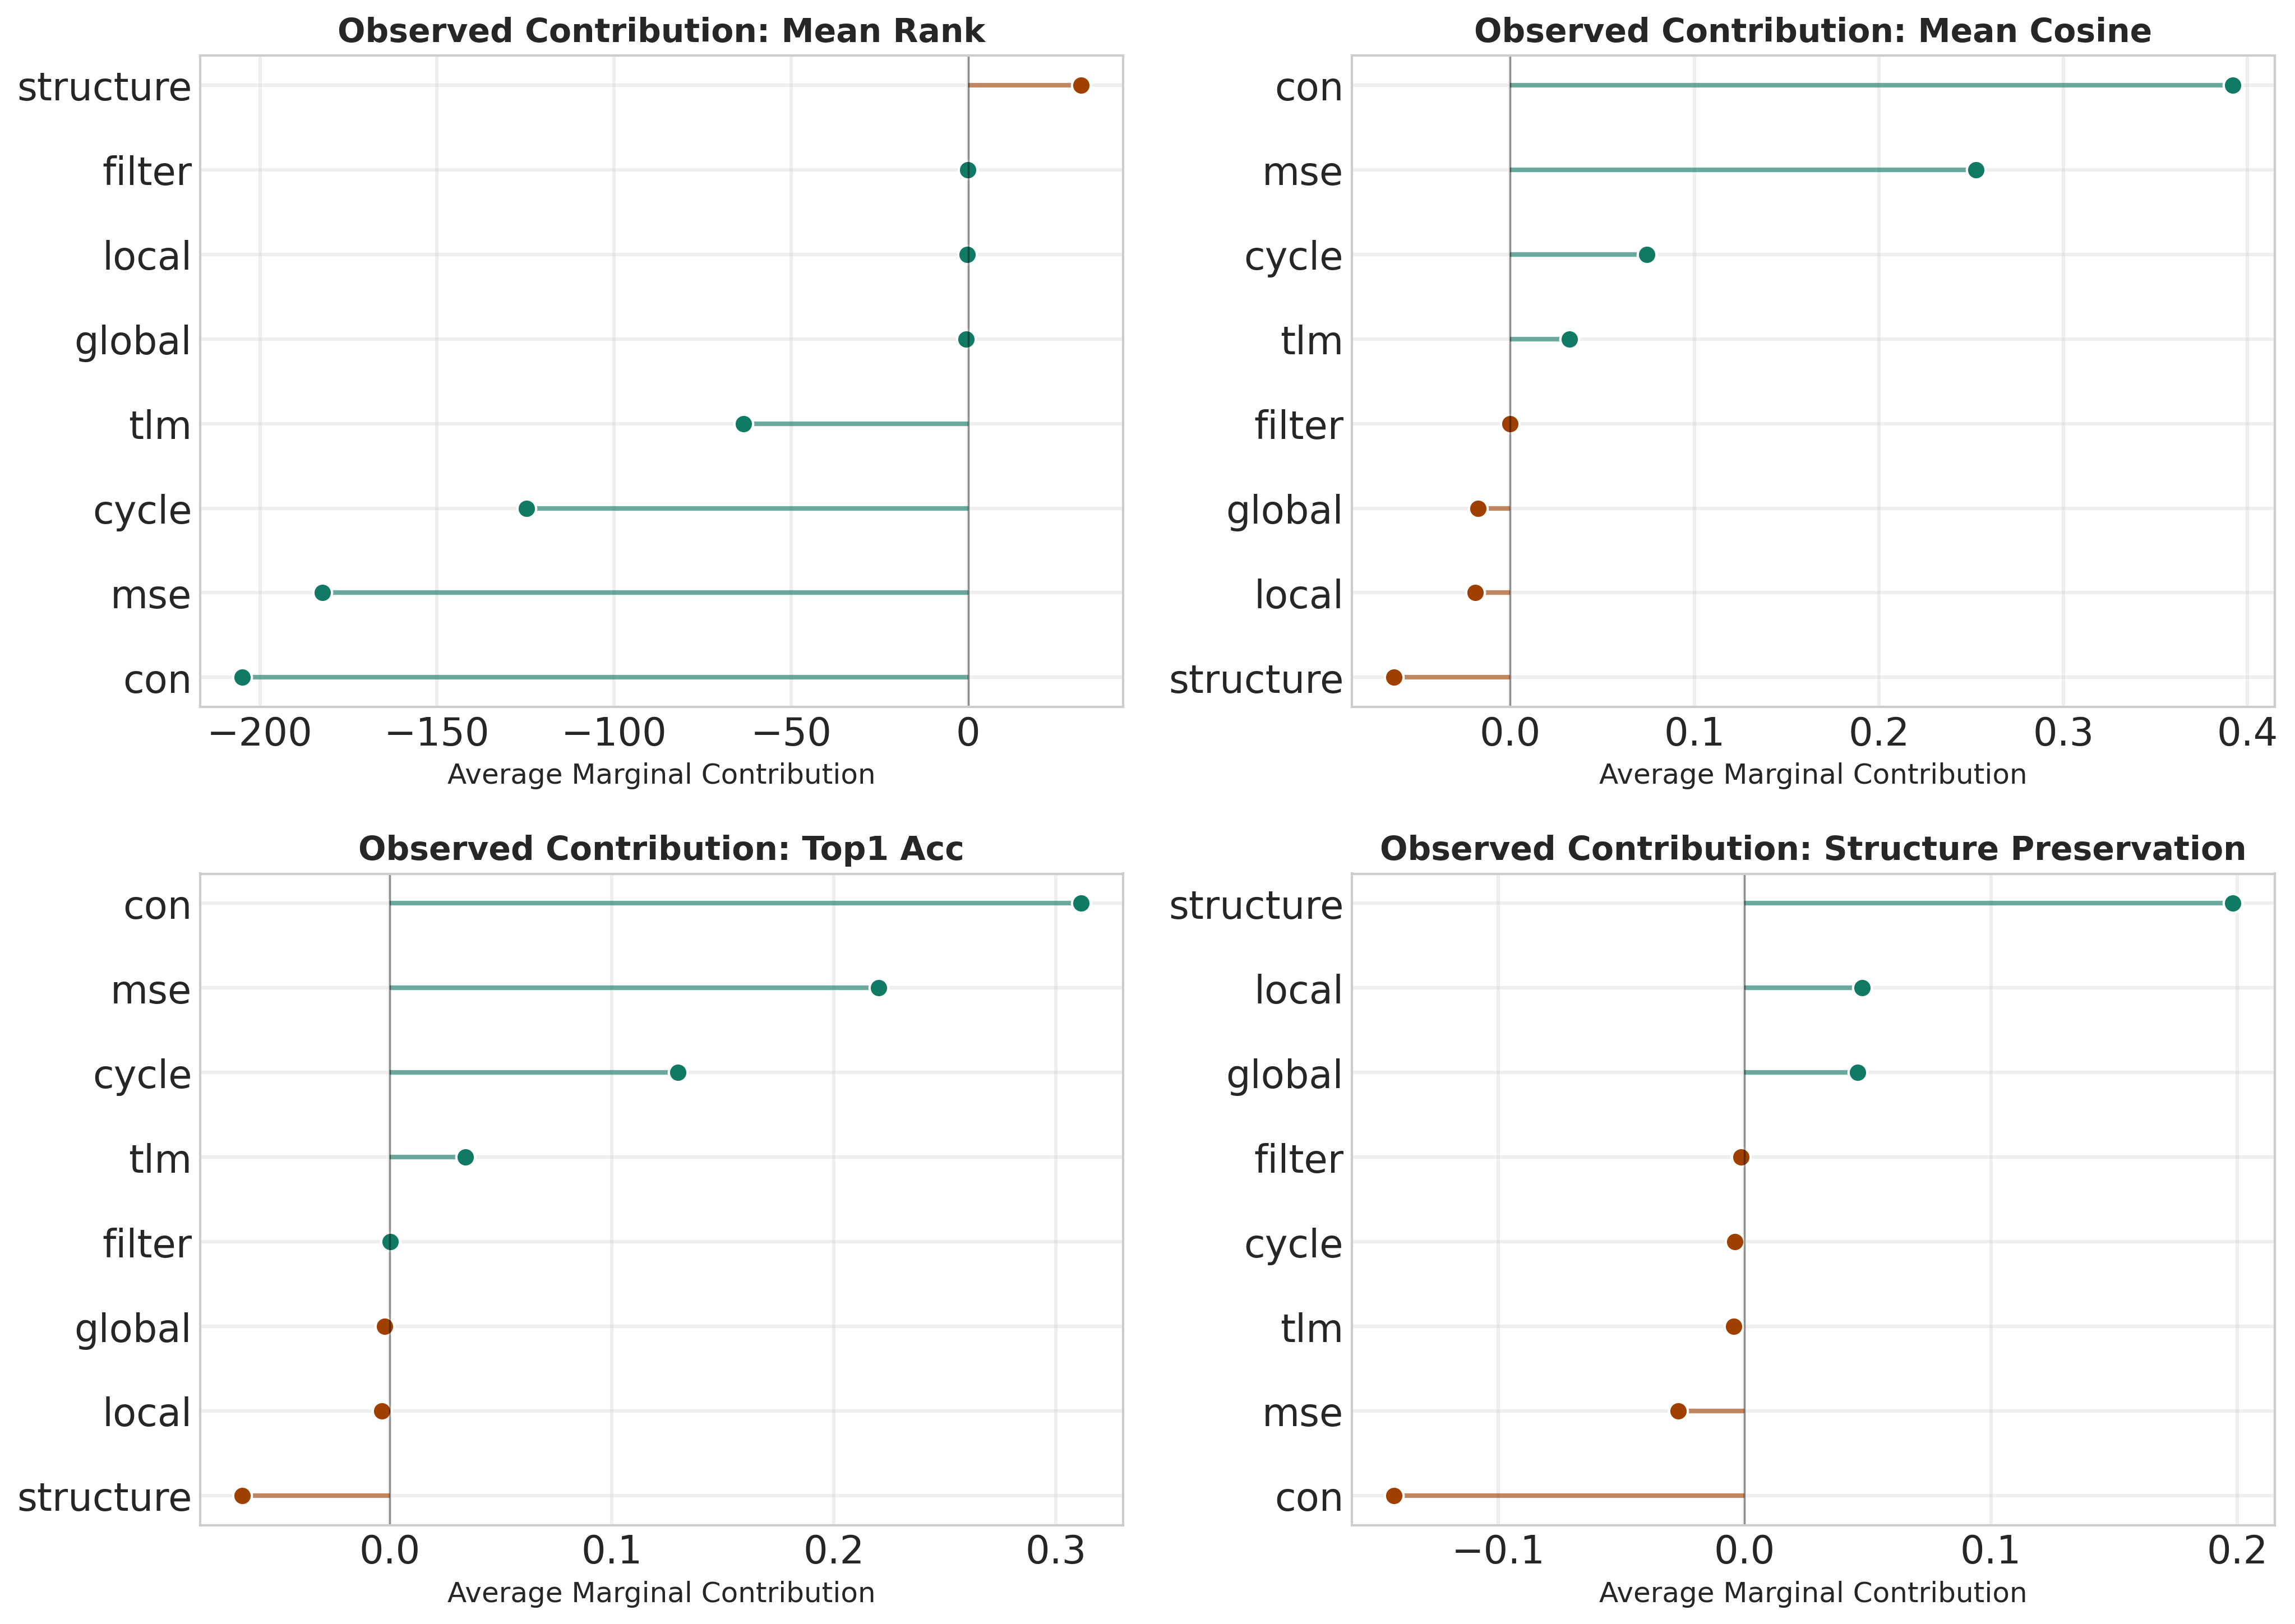


Analysis Complete. Plots saved as 'shapley_results_modern.pdf'.
             configuration  filter  mean_rank  mean_cosine  top1_acc  structure_preservation  mean_rank_norm  combined_score
con+global+local+structure       0        1.0     0.961124       1.0                0.847509             0.0        0.952158
       con+local+structure       0        1.0     0.957222       1.0                0.851256             0.0        0.952120
      con+global+structure       0        1.0     0.956639       1.0                0.850875             0.0        0.951878
   con+local+tlm+structure       0        1.0     0.957418       1.0                0.849220             0.0        0.951659
      con+global+structure       1        1.0     0.956098       1.0                0.850052             0.0        0.951537
   con+local+tlm+structure       1        1.0     0.956370       1.0                0.849556             0.0        0.951482
  con+global+tlm+structure       1        1.0     0.957184  

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Professional Plotting Style ---
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "figure.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.3
})

# ---------------- Load 8 CSVs ----------------
csv_paths = [
    # No Filter
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_100k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_100k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_100k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_200k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_200k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_200k/ablation/ablation_results.csv",
    "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_300k/ablation/ablation_results.csv",
    "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_300k/ablation/ablation_results.csv",
    "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_300k/ablation/ablation_results.csv",
    # Filtered
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_100k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_100k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_100k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_200k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_200k/ablation/ablation_results.csv",
    #"/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_200k/ablation/ablation_results.csv",
    "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_300k/ablation/ablation_results.csv",
    "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_300k/ablation/ablation_results.csv",
    "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_300k/ablation/ablation_results.csv"
]

components = ['structure', 'mse', 'cycle', 'con', 'global', 'local', 'tlm', 'filter']
metrics = ['mean_rank', 'mean_cosine', 'top1_acc', 'structure_preservation']

dfs = []
for i, path in enumerate(csv_paths):
    temp = pd.read_csv(path)
    # Clean column names
    temp.columns = [c.strip() for c in temp.columns]
    # Add the filter component based on file index
    temp["filter"] = 0 if i < 3 else 1
    dfs.append(temp)

df = pd.concat(dfs, ignore_index=True)

# Ensure metrics are floats
for m in metrics:
    df[m] = df[m].astype(str).str.replace(',', '.').astype(float)

# ------------------ Empirical Marginal Contribution Engine ------------------
def compute_observed_contribution(df_subset, metric_name):
    """
    Calculates the average marginal contribution using ONLY observed data pairs.
    It does not guess missing data.
    """
    # Group by components to get unique configurations
    # We use a tuple of the component values as the key (the "mask")
    grouped = df_subset.groupby(components)[metric_name].mean()
    obs_map = grouped.to_dict()
    
    # Store results here
    contributions = {c: [] for c in components}
    
    # Iterate through every actually observed configuration
    for mask_with, score_with in obs_map.items():
        # mask_with is a tuple like (1, 0, 1, ...)
        
        # Check every component in this configuration
        for i, comp_name in enumerate(components):
            # We only care if the component is present (1) in this config
            if mask_with[i] == 1:
                # Create the theoretical "pair" configuration (the one WITHOUT this component)
                mask_without = list(mask_with)
                mask_without[i] = 0
                mask_without = tuple(mask_without)
                
                # CHECK: Did we actually run the experiment without this component?
                if mask_without in obs_map:
                    score_without = obs_map[mask_without]
                    
                    # Calculate difference (Marginal Contribution)
                    delta = score_with - score_without
                    contributions[comp_name].append(delta)

    # Average the contributions found
    final_importance = {}
    for comp in components:
        deltas = contributions[comp]
        if len(deltas) > 0:
            final_importance[comp] = np.mean(deltas)
        else:
            # If no direct pairs were found in the CSVs, contribution is undefined (0)
            final_importance[comp] = 0.0
            
    return final_importance

# ------------------ Process & Visualization ------------------
shap_results = {m: compute_observed_contribution(df, m) for m in metrics}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
POS_COLOR, NEG_COLOR = '#117A65', '#A04000'

for i, m in enumerate(metrics):
    ax = axes[i]
    # Sort by absolute value for a clean "Forest Plot" look
    s_val = pd.Series(shap_results[m]).sort_values()
    y_pos = np.arange(len(s_val))
    
    # Determine which direction is "Good"
    # For mean_rank, lower is better, so a negative contribution is Good (Green)
    is_pos_good = (m != 'mean_rank')
    
    for idx, (comp, val) in enumerate(s_val.items()):
        # Logic: 
        # If High is Good (Acc) AND val > 0 -> Green
        # If Low is Good (Rank) AND val < 0 -> Green
        color = POS_COLOR if (is_pos_good and val > 0) or (not is_pos_good and val < 0) else NEG_COLOR
        
        # Line + Point Style
        ax.hlines(idx, 0, val, color=color, linewidth=2, alpha=0.6)
        ax.plot(val, idx, 'o', color=color, markersize=8, markeredgecolor='white')

    ax.set_yticks(y_pos)
    ax.set_yticklabels(s_val.index)
    ax.axvline(0, color='black', linewidth=0.8, alpha=0.4)
    ax.set_title(f"Observed Contribution: {m.replace('_', ' ').title()}", fontweight='bold')
    ax.set_xlabel("Average Marginal Contribution")

plt.tight_layout()
plt.savefig("4_shapley_results_modern.pdf", bbox_inches='tight')
plt.show()

print("\nAnalysis Complete. Plots saved as 'shapley_results_modern.pdf'.")

# ------------------ TOP 10 (Ranking) ------------------
pivot = df.groupby(["configuration", "filter"])[metrics].mean().reset_index()
# Normalize Rank (0 to 1)
pivot["mean_rank_norm"] = (pivot["mean_rank"] - pivot["mean_rank"].min()) / (pivot["mean_rank"].max() - pivot["mean_rank"].min())

#pivot["mean_cosine_norm"] = (pivot["mean_cosine"] - pivot["mean_cosine"].min()) / (pivot["mean_cosine"].max() - pivot["mean_cosine"].min())
#pivot["structure_norm"] = (pivot["structure_preservation"] - pivot["structure_preservation"].min()) / (pivot["structure_preservation"].max() - pivot["structure_preservation"].min())
#pivot["t1_acc_norm"] = (pivot["top1_acc"] - pivot["top1_acc"].min()) / (pivot["top1_acc"].max() - pivot["top1_acc"].min())

# Calculate Score: 
# We want Low Rank (so we add rank_norm * 0.25). Wait, usually we want to MAXIMIZE score.
# Let's flip rank so 1 is best, 0 is worst for the score calculation:
# Score = (1-Rank_Norm) + Cosine + Structure + Acc
pivot["combined_score"] = (0.25 * (1 - pivot["mean_rank_norm"]) + 
                           0.25 * pivot["mean_cosine"] + 
                           0.25 * pivot["structure_preservation"] + 
                           0.25 * pivot["top1_acc"])
                           #0.25 * pivot["mean_cosine_norm"] + 
                           #0.25 * pivot["structure_norm"] + 
                           #0.25 * pivot["t1_acc_norm"])

print(pivot.sort_values("combined_score", ascending=False).head(10).to_string(index=False))

per sample number

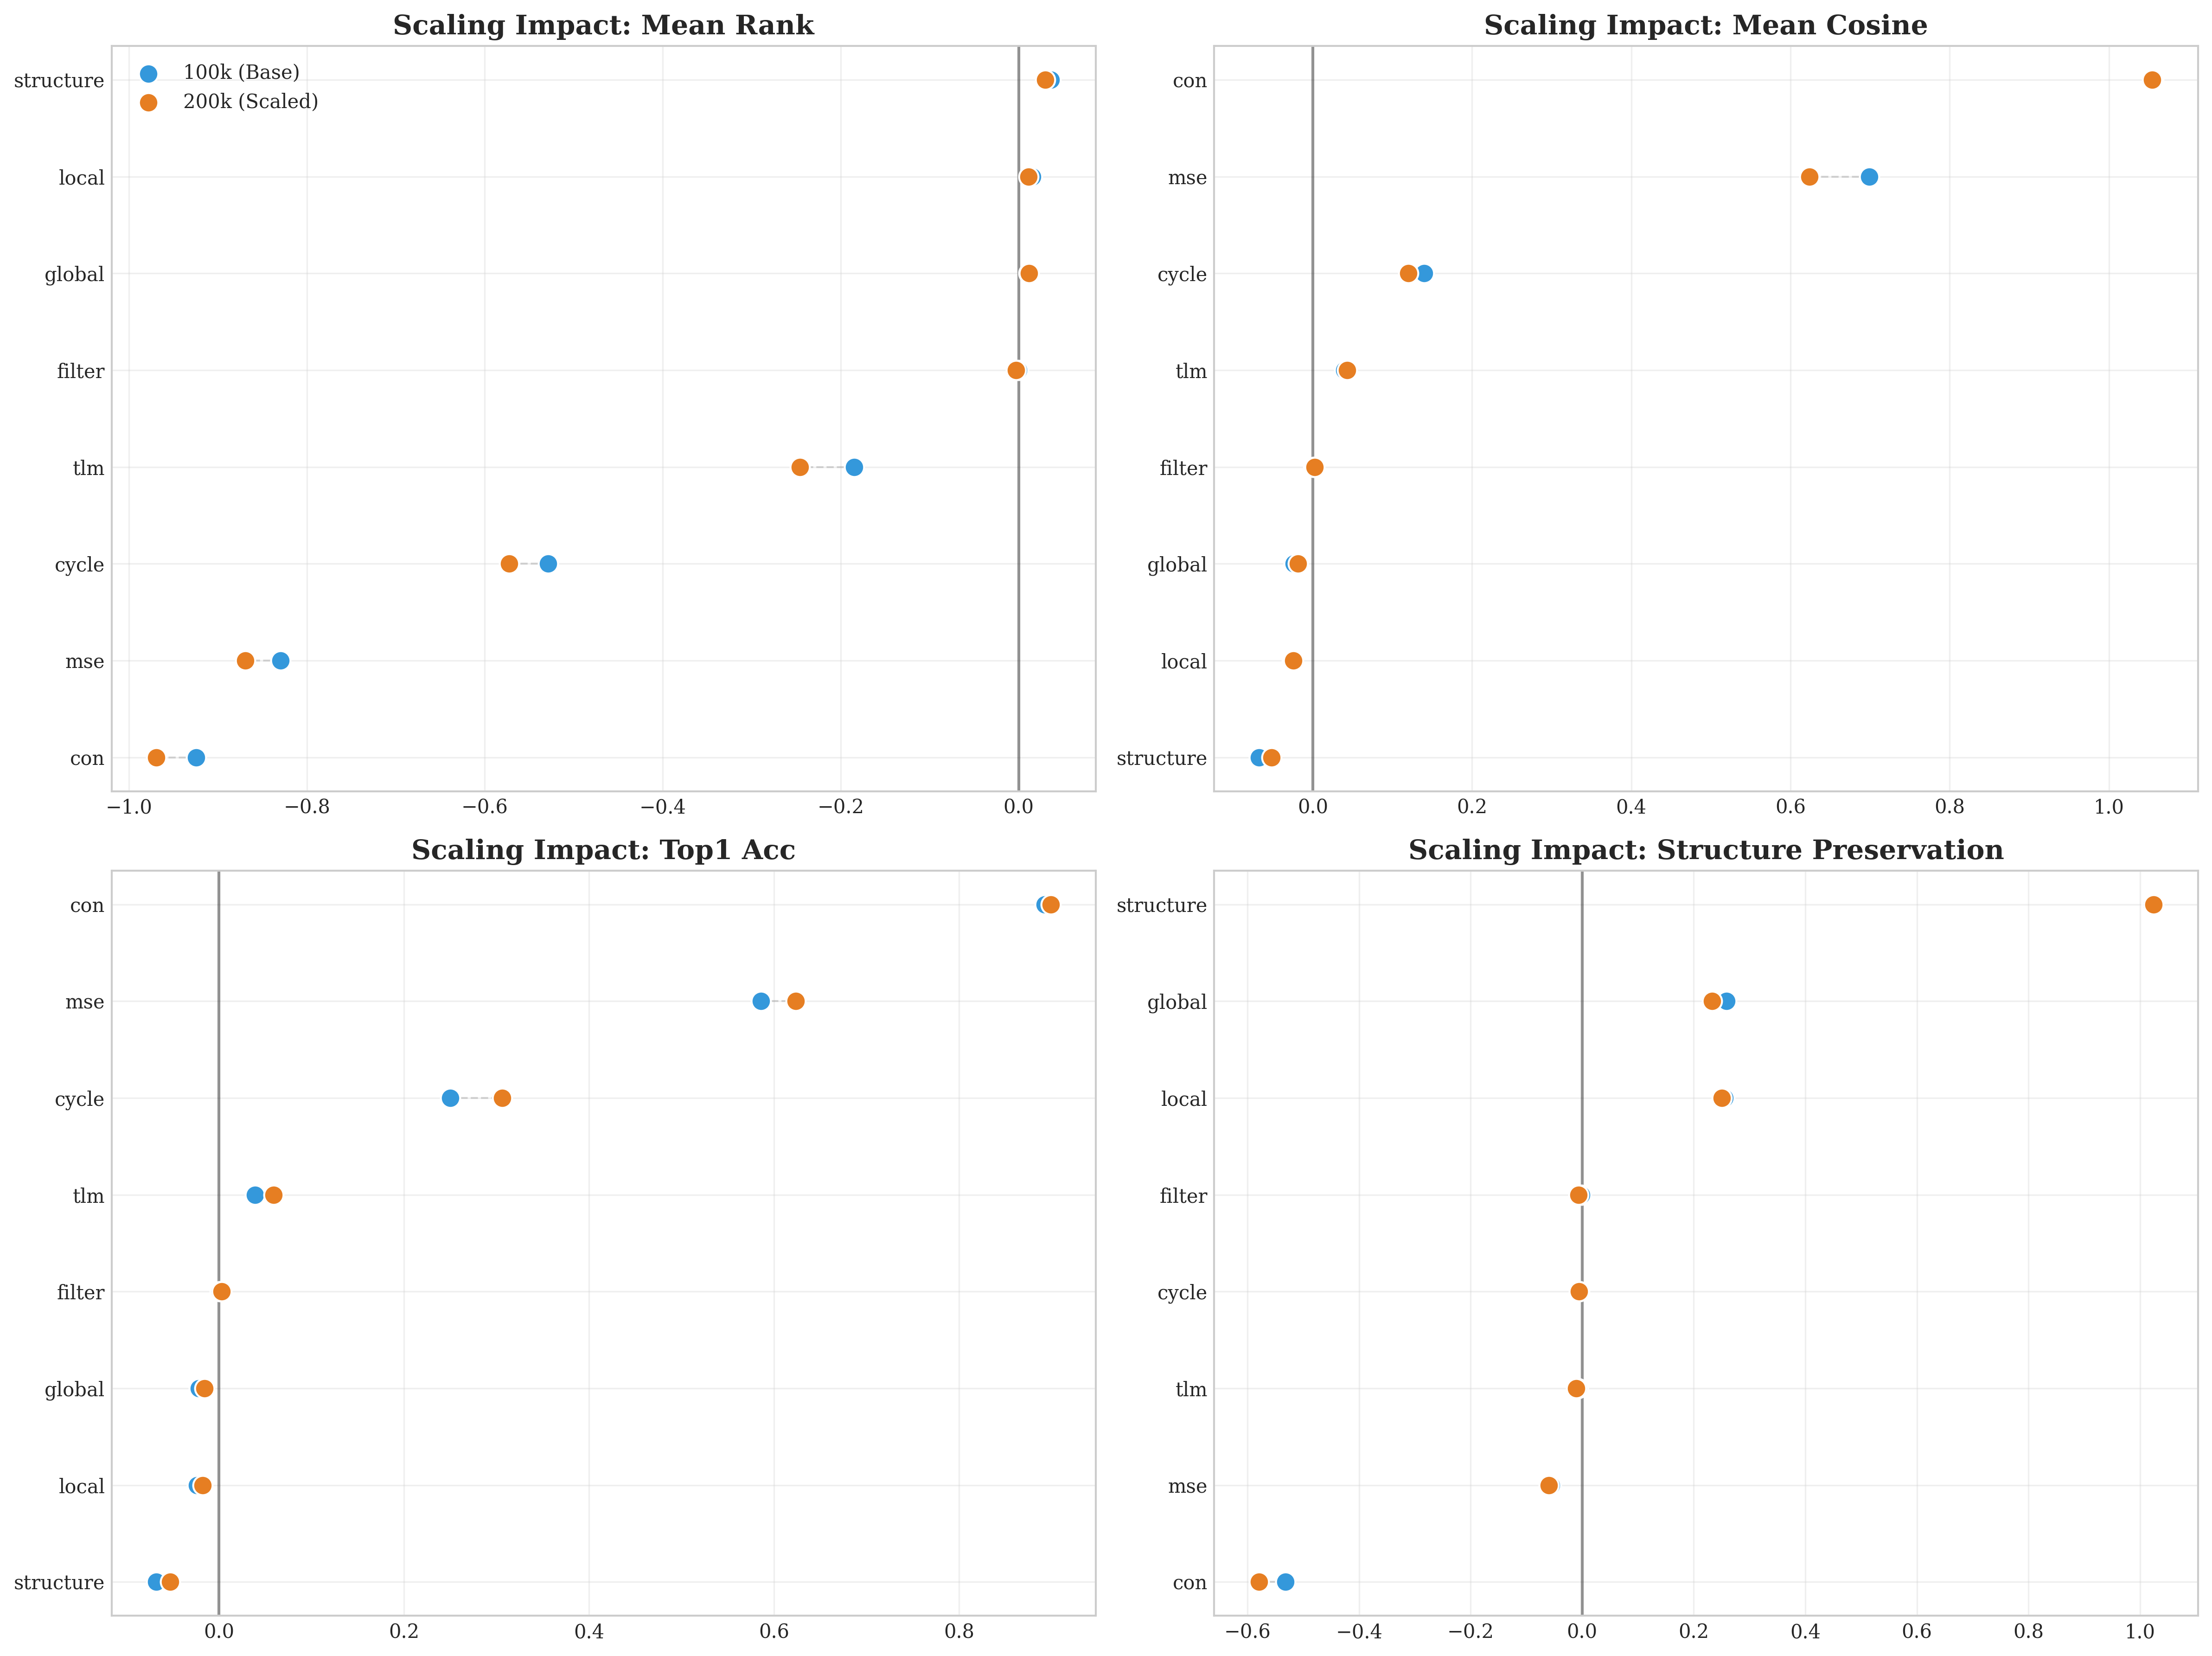

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

# --- Modern Style Configuration (From Code 2) ---
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "figure.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.3
})

components = ['structure', 'mse', 'cycle', 'con', 'global', 'local', 'tlm', 'filter']
metrics = ['mean_rank', 'mean_cosine', 'top1_acc', 'structure_preservation']

# --- Stratified Data Ingestion ---
def load_and_tag(path, size_label, filter_val):
    try:
        df = pd.read_csv(path)
        df.columns = [c.strip() for c in df.columns]
        #df = df[df["direction"] == "src→tgt"].copy()
        # Cleaning
        for m in metrics:
            df[m] = df[m].astype(str).str.replace(',', '.').astype(float)
        # Binary Flags
        for c in [comp for comp in components if comp != 'filter']:
            df[c] = df[c].astype(int)
        # User Required: Explicitly create the filter and size columns
        df["filter"] = filter_val
        df["size"] = size_label
        return df
    except Exception as e:
        print(f"Error loading {path}: {e}")
        return None


## Define 100k Group
#paths_100k_nf = ["/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_100k/ablation/ablation_results.csv", "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_100k/ablation/ablation_results.csv", "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_100k/ablation/ablation_results.csv"]
#paths_100k_f = ["/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_100k/ablation/ablation_results.csv", "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_100k/ablation/ablation_results.csv", "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_100k/ablation/ablation_results.csv"]
#
## Define 200k Group
#paths_200k_nf = ["/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_200k/ablation/ablation_results.csv", "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_200k/ablation/ablation_results.csv", "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_200k/ablation/ablation_results.csv"]
#paths_200k_f = ["/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_200k/ablation/ablation_results.csv", "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_200k/ablation/ablation_results.csv", "/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_gte_200k/ablation/ablation_results.csv"]
#
#df_list = []
#for p in paths_100k_nf: df_list.append(load_and_tag(p, '100k', 0))
#for p in paths_100k_f:  df_list.append(load_and_tag(p, '100k', 1))
#for p in paths_200k_nf: df_list.append(load_and_tag(p, '200k', 0))
#for p in paths_200k_f:  df_list.append(load_and_tag(p, '200k', 1))
#
## Filter out None values in case of loading errors
#df_list = [d for d in df_list if d is not None]
#df_all = pd.concat(df_list, ignore_index=True)

# Map your specific paths
files_to_load = [
    # 100k No Filter
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_100k/ablation/ablation_results.csv", '100k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_100k/ablation/ablation_results.csv", '100k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_100k/ablation/ablation_results.csv", '100k', 0),
    # 200k No Filter
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_200k/ablation/ablation_results.csv", '200k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_200k/ablation/ablation_results.csv", '200k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_200k/ablation/ablation_results.csv", '200k', 0),
    # 100k Filtered
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_100k/ablation/ablation_results.csv", '100k', 1),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_100k/ablation/ablation_results.csv", '100k', 1),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_100k/ablation/ablation_results.csv", '100k', 1),
    # 200k Filtered
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_200k/ablation/ablation_results.csv", '200k', 1),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_200k/ablation/ablation_results.csv", '200k', 1), 
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_200k/ablation/ablation_results.csv", '200k', 1), 
]

df_list = [load_and_tag(p, s, f) for p, s, f in files_to_load]
# Filter out None values in case of loading errors
df_all = pd.concat([d for d in df_list if d is not None], ignore_index=True)

# --- Trend Analysis Engine (Permutation Importance from Code 1) ---
results = {}
for size in ['100k', '200k']:
    subset = df_all[df_all['size'] == size]
    X = subset[components].values
    res_size = {}
    for m in metrics:
        y = subset[m].values
        rf = RandomForestRegressor(n_estimators=500, random_state=42).fit(X, y)
        perm = permutation_importance(rf, X, y, n_repeats=10, random_state=42)
        lr = LinearRegression().fit(StandardScaler().fit_transform(X), y)
        res_size[m] = pd.Series(perm.importances_mean * np.sign(lr.coef_), index=components)
    results[size] = res_size

# --- Visualization: Trend Line Plot (With Code 2 Aesthetics) ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12)) # Updated figsize to match Code 2
axes = axes.flatten()

for i, m in enumerate(metrics):
    ax = axes[i]
    s100 = results['100k'][m].sort_values()
    s200 = results['200k'][m][s100.index]
    y_pos = np.arange(len(components))
    
    # Modern Dot-Line Trend Style
    ax.hlines(y_pos, s100, s200, color='grey', alpha=0.3, linestyle='--', linewidth=1)
    ax.scatter(s100, y_pos, color='#3498db', label='100k (Base)', s=100, edgecolors='white', zorder=3)
    ax.scatter(s200, y_pos, color='#e67e22', label='200k (Scaled)', s=100, edgecolors='white', zorder=3)
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(s100.index)
    ax.axvline(0, color='black', alpha=0.4)
    
    # Title with bold font weight (from Code 2 style)
    ax.set_title(f"Scaling Impact: {m.replace('_', ' ').title()}", fontweight='bold')
    
    if i == 0: ax.legend()

plt.tight_layout()
plt.savefig("scaling_trend_forest_plot_styled.pdf")
plt.show()

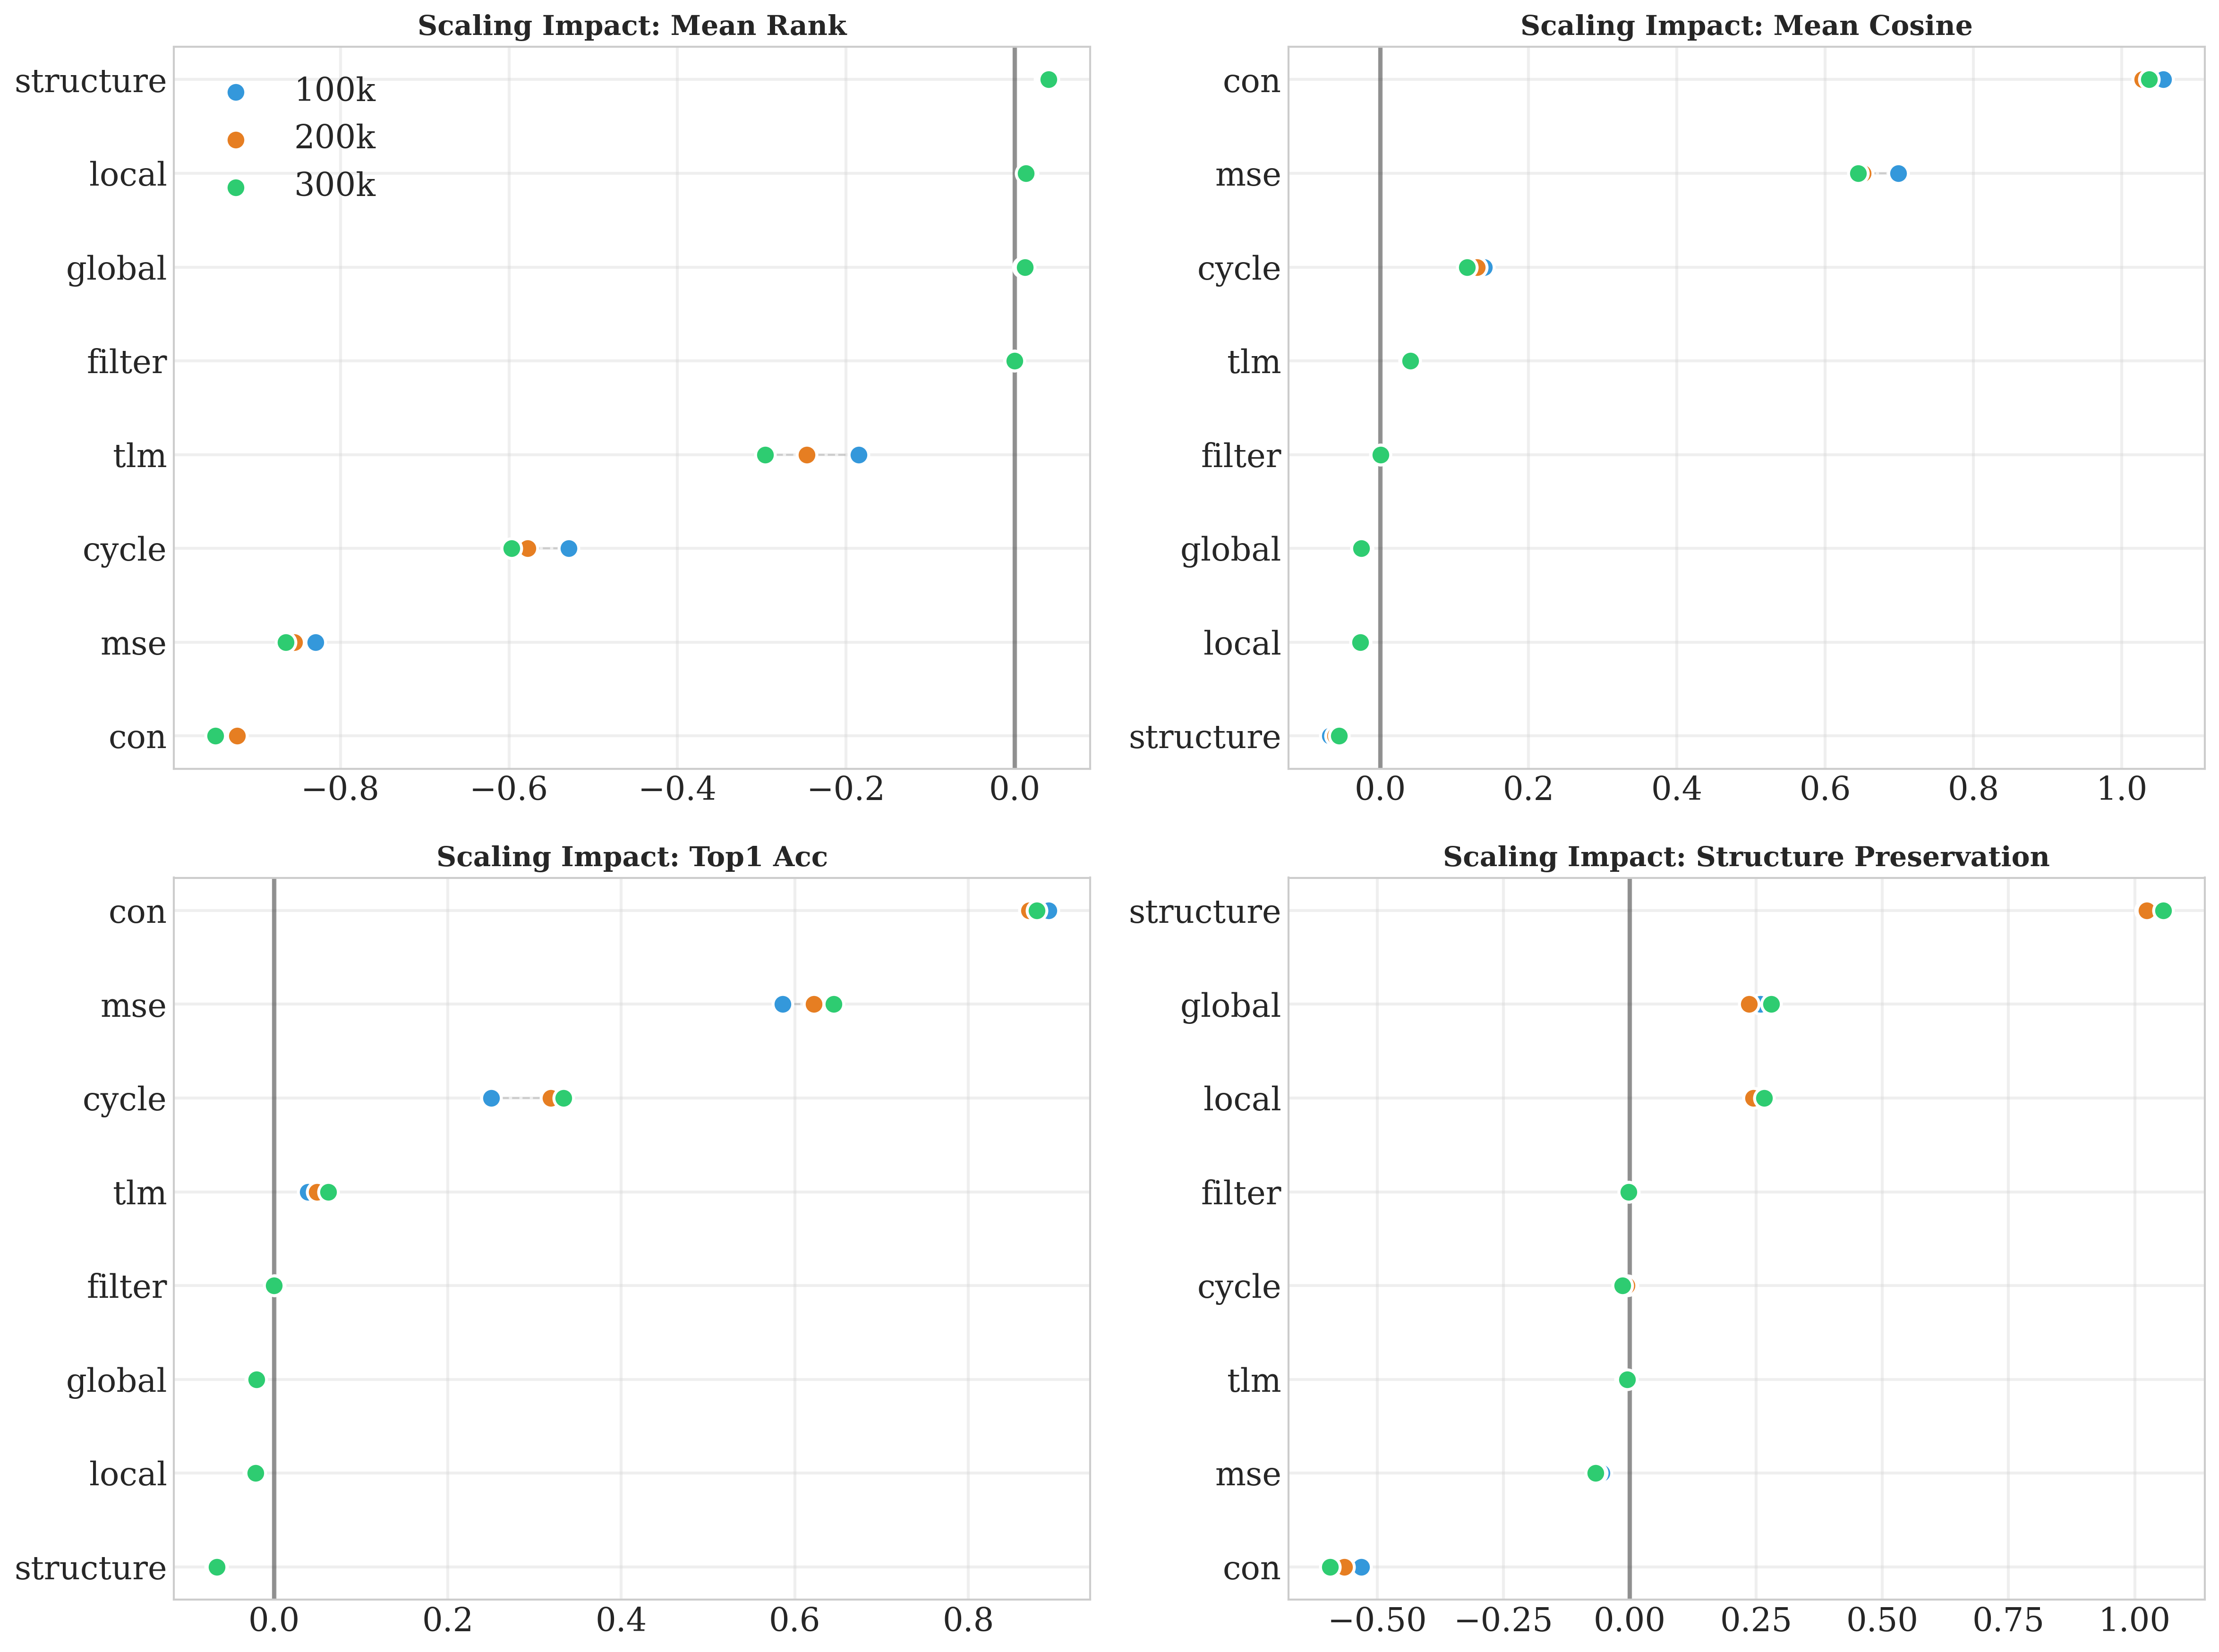

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

# --- Modern Style Configuration ---
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "figure.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.3
})

components = ['structure', 'mse', 'cycle', 'con', 'global', 'local', 'tlm', 'filter']
metrics = ['mean_rank', 'mean_cosine', 'top1_acc', 'structure_preservation']

# --- Stratified Data Ingestion ---
def load_and_tag(path, size_label, filter_val):
    try:
        df = pd.read_csv(path)
        df.columns = [c.strip() for c in df.columns]
        # Cleaning
        for m in metrics:
            df[m] = df[m].astype(str).str.replace(',', '.').astype(float)
        # Binary Flags
        for c in [comp for comp in components if comp != 'filter']:
            df[c] = df[c].astype(int)
        # User Required: Explicitly create the filter and size columns
        df["filter"] = filter_val
        df["size"] = size_label
        return df
    except Exception as e:
        print(f"Error loading {path}: {e}")
        return None

# Map your specific paths (Includes 300k)
files_to_load = [
    # 100k No Filter
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_100k/ablation/ablation_results.csv", '100k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_100k/ablation/ablation_results.csv", '100k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_100k/ablation/ablation_results.csv", '100k', 0),
    # 200k No Filter
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_200k/ablation/ablation_results.csv", '200k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_200k/ablation/ablation_results.csv", '200k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_200k/ablation/ablation_results.csv", '200k', 0),
    # 300k No Filter
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_300k/ablation/ablation_results.csv", '300k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_300k/ablation/ablation_results.csv", '300k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_300k/ablation/ablation_results.csv", '300k', 0),
    # 100k Filtered
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_100k/ablation/ablation_results.csv", '100k', 1),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_100k/ablation/ablation_results.csv", '100k', 1),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_100k/ablation/ablation_results.csv", '100k', 1),
    # 200k Filtered
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_200k/ablation/ablation_results.csv", '200k', 1),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_200k/ablation/ablation_results.csv", '200k', 1), 
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_200k/ablation/ablation_results.csv", '200k', 1), 
    # 300k Filtered
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_300k/ablation/ablation_results.csv", '300k', 1),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_300k/ablation/ablation_results.csv", '300k', 1), 
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_300k/ablation/ablation_results.csv", '300k', 1)
]

df_list = [load_and_tag(p, s, f) for p, s, f in files_to_load]
# Filter out None values in case of loading errors
df_all = pd.concat([d for d in df_list if d is not None], ignore_index=True)

# --- Trend Analysis Engine (Permutation Importance) ---
results = {}
# UPDATED: Loop now includes '300k'
for size in ['100k', '200k', '300k']:
    subset = df_all[df_all['size'] == size]
    
    # Safety check if 300k data loaded correctly
    if subset.empty:
        print(f"Warning: No data found for size {size}")
        continue
        
    X = subset[components].values
    res_size = {}
    for m in metrics:
        y = subset[m].values
        rf = RandomForestRegressor(n_estimators=500, random_state=42).fit(X, y)
        perm = permutation_importance(rf, X, y, n_repeats=10, random_state=42)
        lr = LinearRegression().fit(StandardScaler().fit_transform(X), y)
        res_size[m] = pd.Series(perm.importances_mean * np.sign(lr.coef_), index=components)
    results[size] = res_size

# --- Visualization: Trend Line Plot ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12)) 
axes = axes.flatten()

for i, m in enumerate(metrics):
    ax = axes[i]
    
    # 1. Get Base (100k) and sort by it
    if '100k' in results:
        s100 = results['100k'][m].sort_values()
        y_pos = np.arange(len(components))
    else:
        continue # Skip if base data missing

    # 2. Get other scales using the index of s100 for alignment
    s200 = results['200k'][m][s100.index] if '200k' in results else pd.Series(0, index=s100.index)
    s300 = results['300k'][m][s100.index] if '300k' in results else pd.Series(0, index=s100.index)
    
    # 3. Calculate range for the connecting line (min to max of all 3 points)
    # We combine them into a dataframe to easily find min/max per row
    combined_scores = pd.concat([s100, s200, s300], axis=1)
    min_vals = combined_scores.min(axis=1)
    max_vals = combined_scores.max(axis=1)
    
    # Modern Dot-Line Trend Style
    # Draw line from lowest point to highest point
    ax.hlines(y_pos, min_vals, max_vals, color='grey', alpha=0.3, linestyle='--', linewidth=1)
    
    # Plot Points
    ax.scatter(s100, y_pos, color='#3498db', label='100k', s=100, edgecolors='white', zorder=3)
    ax.scatter(s200, y_pos, color='#e67e22', label='200k', s=100, edgecolors='white', zorder=3)
    # New 300k Point (Green)
    ax.scatter(s300, y_pos, color='#2ecc71', label='300k', s=100, edgecolors='white', zorder=3)
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(s100.index)
    ax.axvline(0, color='black', alpha=0.4)
    
    ax.set_title(f"Scaling Impact: {m.replace('_', ' ').title()}", fontweight='bold')
    
    if i == 0: ax.legend()

plt.tight_layout()
plt.savefig("5_scaling_trend_forest_plot_300k.pdf")
plt.show()

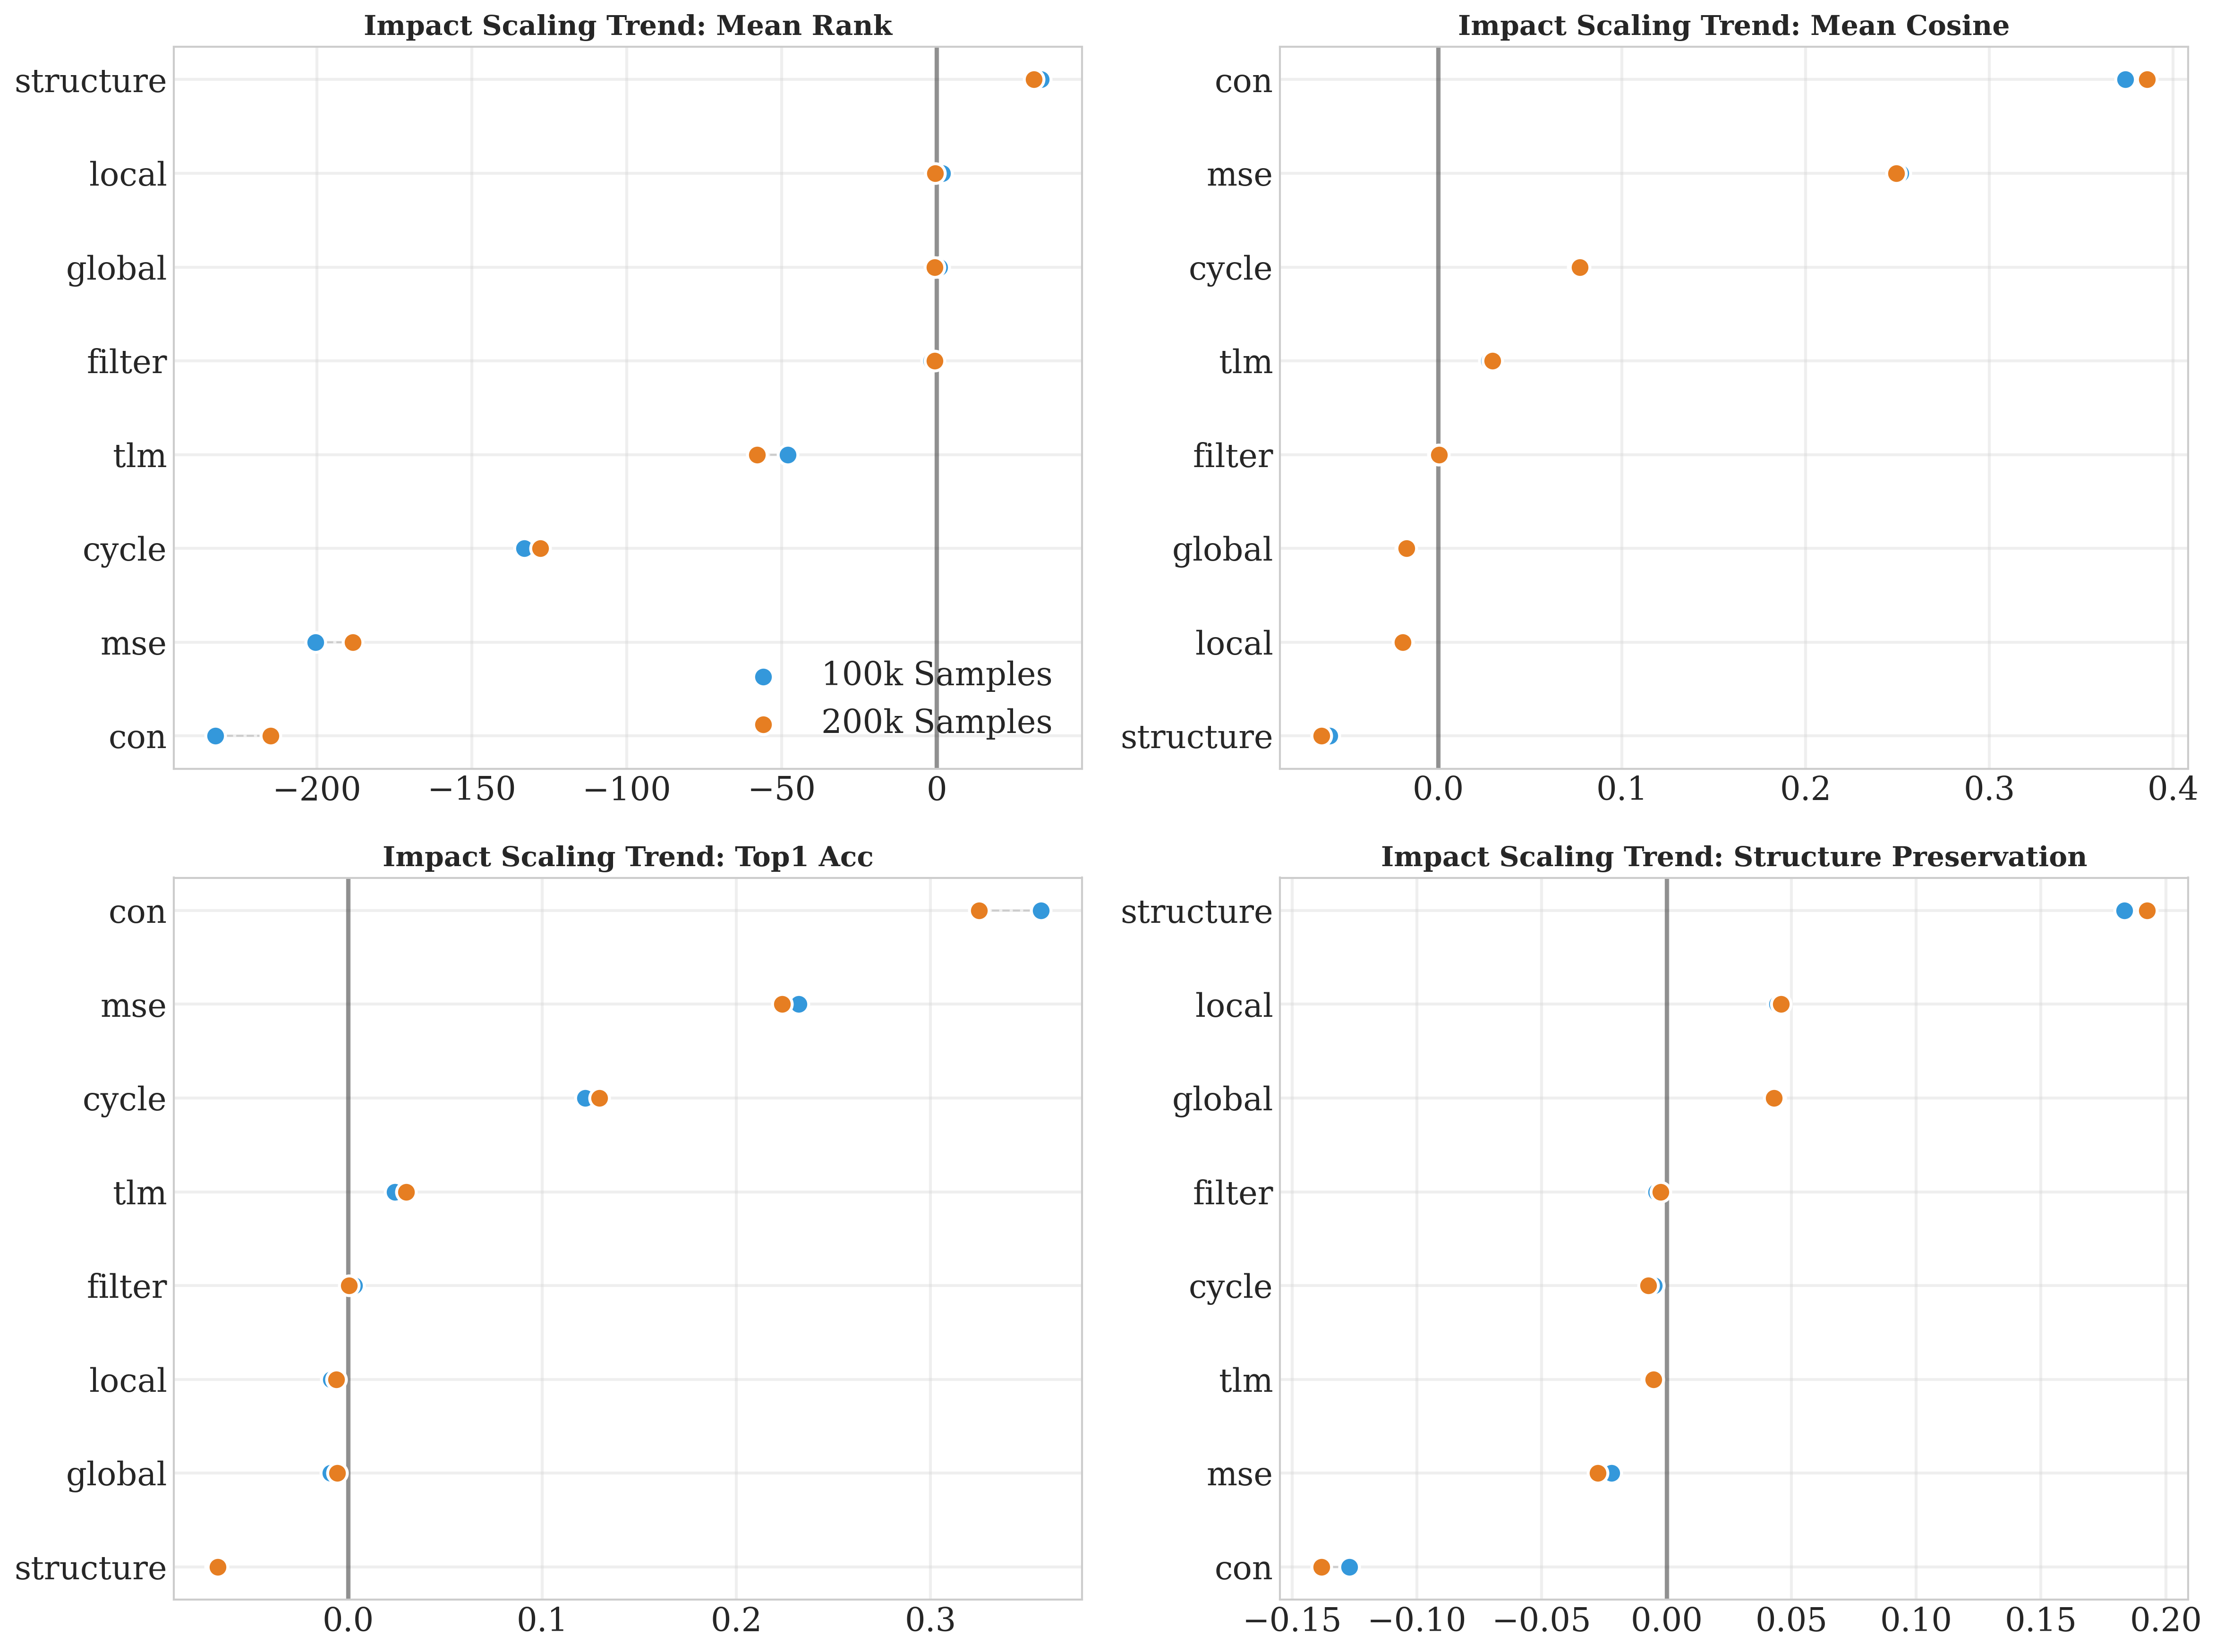

Analysis Complete. Plot saved as 'shapley_scaling_trend_final.pdf'.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Modern Style Configuration ---
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "figure.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.3
})

components = ['structure', 'mse', 'cycle', 'con', 'global', 'local', 'tlm', 'filter']
metrics = ['mean_rank', 'mean_cosine', 'top1_acc', 'structure_preservation']

# ------------------ 1. Data Ingestion & Tagging ------------------
def load_and_tag(path, size_label, filter_val):
    try:
        df = pd.read_csv(path)
        df.columns = [c.strip() for c in df.columns]
        #df = df[df["direction"] == "src→tgt"].copy()
        
        # Ensure metrics are floats
        for m in metrics:
            df[m] = df[m].astype(str).str.replace(',', '.').astype(float)
            
        # Ensure component columns (except filter) are ints
        for c in [comp for comp in components if comp != 'filter']:
            df[c] = df[c].astype(int)
            
        df["filter"] = filter_val
        df["size"] = size_label
        return df
    except Exception as e:
        print(f"Error loading {path}: {e}")
        return None

# Map your specific paths
files_to_load = [
    # 100k No Filter
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_100k/ablation/ablation_results.csv", '100k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_100k/ablation/ablation_results.csv", '100k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_100k/ablation/ablation_results.csv", '100k', 0),
    # 200k No Filter
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_200k/ablation/ablation_results.csv", '200k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_200k/ablation/ablation_results.csv", '200k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_200k/ablation/ablation_results.csv", '200k', 0),
    # 300k No Filter
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_300k/ablation/ablation_results.csv", '300k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_300k/ablation/ablation_results.csv", '300k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_300k/ablation/ablation_results.csv", '300k', 0),
    # 100k Filtered
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_100k/ablation/ablation_results.csv", '100k', 1),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_100k/ablation/ablation_results.csv", '100k', 1),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_100k/ablation/ablation_results.csv", '100k', 1),
    # 200k Filtered
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_200k/ablation/ablation_results.csv", '200k', 1),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_200k/ablation/ablation_results.csv", '200k', 1), 
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_200k/ablation/ablation_results.csv", '200k', 1), 
    # 300k Filtered
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_300k/ablation/ablation_results.csv", '300k', 1),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_300k/ablation/ablation_results.csv", '300k', 1), 
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_300k/ablation/ablation_results.csv", '300k', 1)
]

df_list = [load_and_tag(p, s, f) for p, s, f in files_to_load]
# Filter out None values in case of loading errors
df_all = pd.concat([d for d in df_list if d is not None], ignore_index=True)

# ------------------ 2. Observed Contribution Logic (No Imputation) ------------------
def compute_observed_contribution(df_subset, metric_name):
    """
    Calculates impact by looking at differences between pairs of experiments
    that actually exist in the CSVs. No Random Forest guessing.
    """
    # 1. Group by unique component configuration
    obs_map = df_subset.groupby(components)[metric_name].mean().to_dict()
    
    # Store deltas (differences) here
    contributions = {c: [] for c in components}
    
    # 2. Iterate through every actually observed configuration
    for mask_with, score_with in obs_map.items():
        # mask_with is a tuple of 0s and 1s, e.g., (1, 0, 1, ...) representing the config
        
        # Check every component 'i' in this configuration
        for i, comp_name in enumerate(components):
            # We are looking for the marginal contribution of having component 'i' ON.
            # So, we check if 'i' is currently ON (1).
            if mask_with[i] == 1:
                # Create the theoretical "pair" configuration (same config but with component 'i' OFF)
                mask_without = list(mask_with)
                mask_without[i] = 0
                mask_without = tuple(mask_without)
                
                # STRICT CHECK: Did we actually run the experiment without this component?
                if mask_without in obs_map:
                    score_without = obs_map[mask_without]
                    
                    # The impact is (Score with Component) - (Score without Component)
                    delta = score_with - score_without
                    contributions[comp_name].append(delta)

    # 3. Average the deltas we found
    final_importance = {}
    for comp in components:
        deltas = contributions[comp]
        if len(deltas) > 0:
            final_importance[comp] = np.mean(deltas)
        else:
            # If we never ran a pair of experiments to test this specific component in isolation,
            # we cannot know its contribution from the data alone. Set to 0.
            final_importance[comp] = 0.0
            
    return final_importance

# ------------------ 3. Execution ------------------
# Compute contributions separately for 100k and 200k datasets
results_100k = {m: compute_observed_contribution(df_all[df_all['size'] == '100k'], m) for m in metrics}
results_200k = {m: compute_observed_contribution(df_all[df_all['size'] == '200k'], m) for m in metrics}

# ------------------ 4. Trend Visualization ------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, m in enumerate(metrics):
    ax = axes[i]
    
    # Sort based on 100k results to establish order
    s100 = pd.Series(results_100k[m]).sort_values()
    # Match the order for 200k results
    s200 = pd.Series(results_200k[m])[s100.index]
    
    y_pos = np.arange(len(components))
    
    # Plot connecting lines between 100k and 200k dots
    ax.hlines(y_pos, s100, s200, color='grey', alpha=0.3, linestyle='--', linewidth=1)
    
    # Plot the dots
    ax.scatter(s100, y_pos, color='#3498db', label='100k Samples', s=100, edgecolors='white', zorder=3)
    ax.scatter(s200, y_pos, color='#e67e22', label='200k Samples', s=100, edgecolors='white', zorder=3)
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(s100.index)
    ax.axvline(0, color='black', alpha=0.4)
    ax.set_title(f"Impact Scaling Trend: {m.replace('_', ' ').title()}", fontweight='bold')
    
    if i == 0: 
        ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig("shapley_scaling_trend_final.pdf")
plt.show()

print("Analysis Complete. Plot saved as 'shapley_scaling_trend_final.pdf'.")

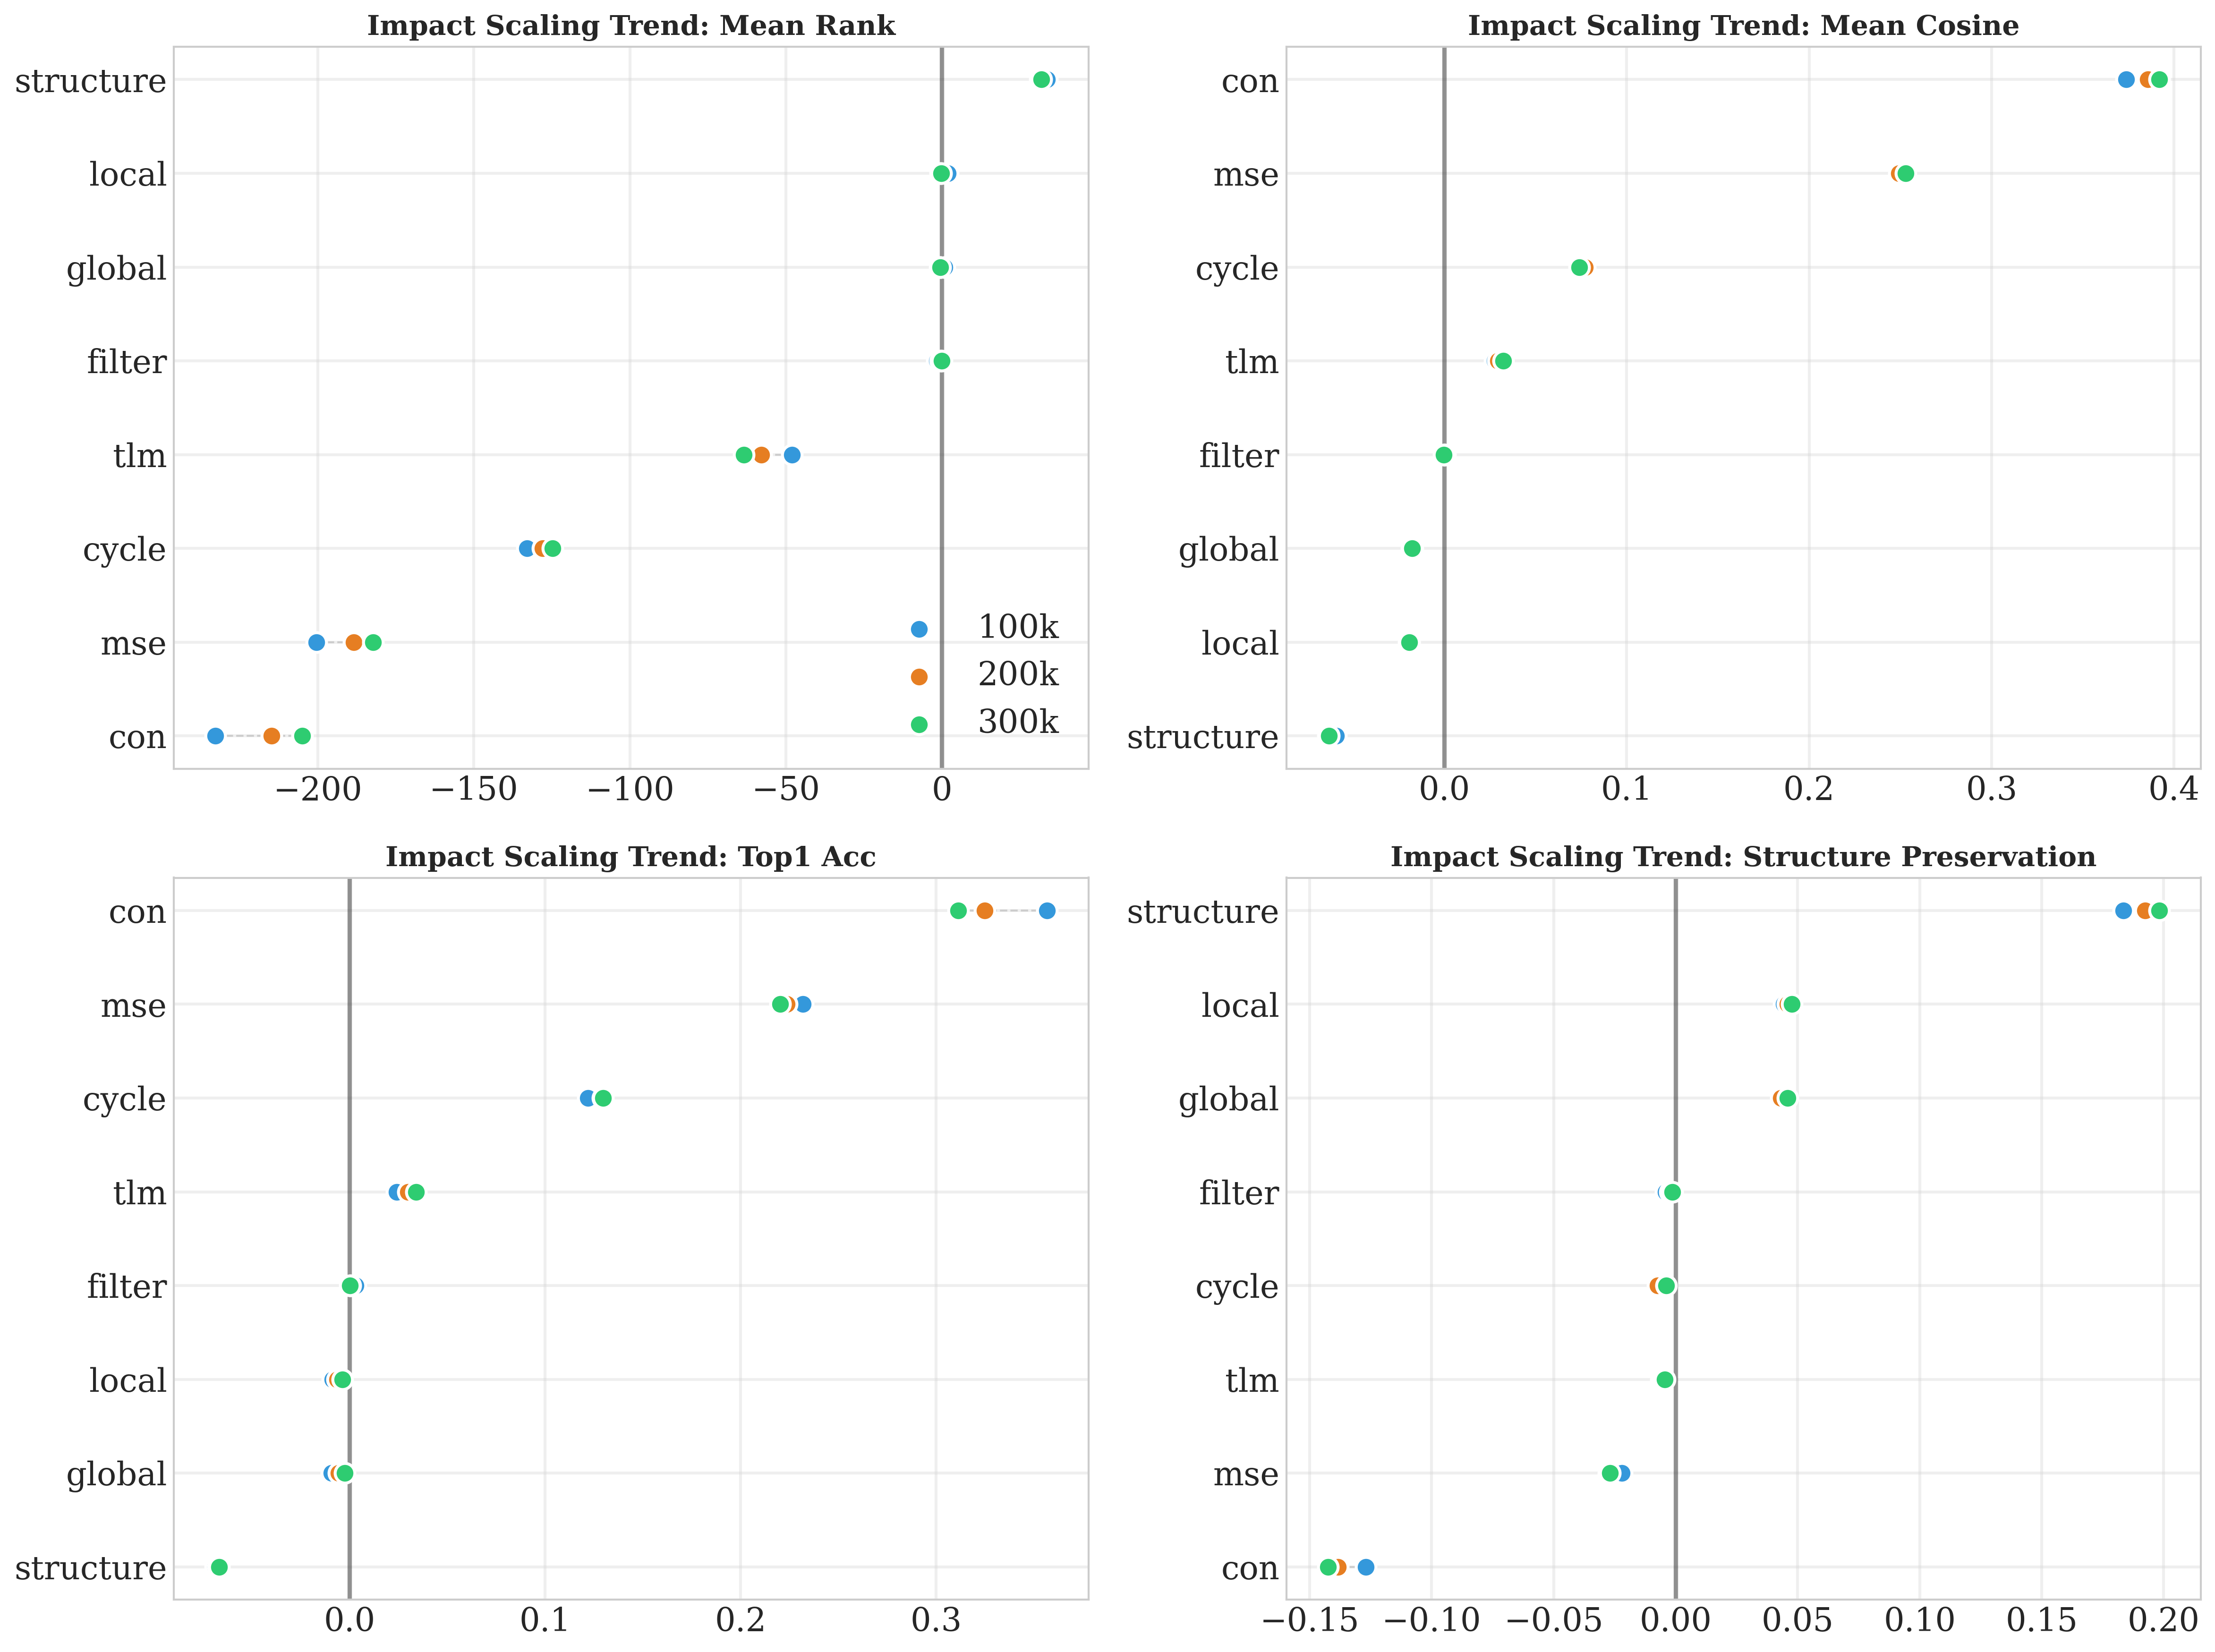

Analysis Complete. Plot saved as 'shapley_scaling_trend_final_300k.pdf'.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Modern Style Configuration ---
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "figure.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.3
})

components = ['structure', 'mse', 'cycle', 'con', 'global', 'local', 'tlm', 'filter']
metrics = ['mean_rank', 'mean_cosine', 'top1_acc', 'structure_preservation']

# ------------------ 1. Data Ingestion & Tagging ------------------
def load_and_tag(path, size_label, filter_val):
    try:
        df = pd.read_csv(path)
        df.columns = [c.strip() for c in df.columns]
        
        # Ensure metrics are floats
        for m in metrics:
            df[m] = df[m].astype(str).str.replace(',', '.').astype(float)
            
        # Ensure component columns (except filter) are ints
        for c in [comp for comp in components if comp != 'filter']:
            df[c] = df[c].astype(int)
            
        df["filter"] = filter_val
        df["size"] = size_label
        return df
    except Exception as e:
        print(f"Error loading {path}: {e}")
        return None

# Map your specific paths (Includes 300k)
files_to_load = [
    # 100k No Filter
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_100k/ablation/ablation_results.csv", '100k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_100k/ablation/ablation_results.csv", '100k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_100k/ablation/ablation_results.csv", '100k', 0),
    # 200k No Filter
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_200k/ablation/ablation_results.csv", '200k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_200k/ablation/ablation_results.csv", '200k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_200k/ablation/ablation_results.csv", '200k', 0),
    # 300k No Filter
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_qwen_gtel_300k/ablation/ablation_results.csv", '300k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gra_gte_300k/ablation/ablation_results.csv", '300k', 0),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_cross_attention_no_filter_correct_gtr_e5_300k/ablation/ablation_results.csv", '300k', 0),
    # 100k Filtered
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_100k/ablation/ablation_results.csv", '100k', 1),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_100k/ablation/ablation_results.csv", '100k', 1),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_100k/ablation/ablation_results.csv", '100k', 1),
    # 200k Filtered
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_200k/ablation/ablation_results.csv", '200k', 1),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_200k/ablation/ablation_results.csv", '200k', 1), 
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_200k/ablation/ablation_results.csv", '200k', 1), 
    # 300k Filtered
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_qwen_gtel_300k/ablation/ablation_results.csv", '300k', 1),
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gra_gte_300k/ablation/ablation_results.csv", '300k', 1), 
    ("/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/ablation_study/saved_mappers_diverse_optimized_correct_gtr_e5_300k/ablation/ablation_results.csv", '300k', 1)
]

df_list = [load_and_tag(p, s, f) for p, s, f in files_to_load]
df_all = pd.concat([d for d in df_list if d is not None], ignore_index=True)

# ------------------ 2. Observed Contribution Logic ------------------
def compute_observed_contribution(df_subset, metric_name):
    """
    Calculates impact by looking at differences between pairs of experiments
    that actually exist in the CSVs.
    """
    if df_subset.empty:
        return {c: 0.0 for c in components} # Handle missing data gracefully

    obs_map = df_subset.groupby(components)[metric_name].mean().to_dict()
    contributions = {c: [] for c in components}
    
    for mask_with, score_with in obs_map.items():
        for i, comp_name in enumerate(components):
            if mask_with[i] == 1:
                mask_without = list(mask_with)
                mask_without[i] = 0
                mask_without = tuple(mask_without)
                
                if mask_without in obs_map:
                    score_without = obs_map[mask_without]
                    delta = score_with - score_without
                    contributions[comp_name].append(delta)

    final_importance = {}
    for comp in components:
        deltas = contributions[comp]
        final_importance[comp] = np.mean(deltas) if len(deltas) > 0 else 0.0
            
    return final_importance

# ------------------ 3. Execution ------------------
# Compute contributions separately for 100k, 200k, and 300k datasets
results_100k = {m: compute_observed_contribution(df_all[df_all['size'] == '100k'], m) for m in metrics}
results_200k = {m: compute_observed_contribution(df_all[df_all['size'] == '200k'], m) for m in metrics}
results_300k = {m: compute_observed_contribution(df_all[df_all['size'] == '300k'], m) for m in metrics}

# ------------------ 4. Trend Visualization ------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, m in enumerate(metrics):
    ax = axes[i]
    
    # Sort based on 100k results
    s100 = pd.Series(results_100k[m]).sort_values()
    # Align others to this index
    s200 = pd.Series(results_200k[m])[s100.index]
    s300 = pd.Series(results_300k[m])[s100.index]
    
    y_pos = np.arange(len(components))
    
    # Calculate range for connecting lines (min to max of the 3 points)
    combined = pd.concat([s100, s200, s300], axis=1)
    min_vals = combined.min(axis=1)
    max_vals = combined.max(axis=1)
    
    # Plot connecting lines
    ax.hlines(y_pos, min_vals, max_vals, color='grey', alpha=0.3, linestyle='--', linewidth=1)
    
    # Plot the dots
    ax.scatter(s100, y_pos, color='#3498db', label='100k', s=100, edgecolors='white', zorder=3)
    ax.scatter(s200, y_pos, color='#e67e22', label='200k', s=100, edgecolors='white', zorder=3)
    ax.scatter(s300, y_pos, color='#2ecc71', label='300k', s=100, edgecolors='white', zorder=3)
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(s100.index)
    ax.axvline(0, color='black', alpha=0.4)
    ax.set_title(f"Impact Scaling Trend: {m.replace('_', ' ').title()}", fontweight='bold')
    
    if i == 0: 
        ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig("6_shapley_scaling_trend_final_300k.pdf")
plt.show()

print("Analysis Complete. Plot saved as 'shapley_scaling_trend_final_300k.pdf'.")